<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/HybridQNN_AccuracyRobustness_Tran2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QCNN, QRNN and QViT under adversarial attack and quantum noise: Tran et al. (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Ban Q. Tran, Duong M. Chu, Hai T. D. Pham, Viet Q. Nguyen, Quan A. Pham and Susan Mengel,
> "A Comprehensive Analysis of Accuracy and Robustness in Quantum Neural Networks",
> arXiv:2604.26110 [quant-ph], 28 April 2026. DOI 10.48550/arxiv.2604.26110. https://arxiv.org/abs/2604.26110

The paper publishes no code, so everything below is written from its description with the software it names (PennyLane, Adam,
the APGD attack). Where the paper is silent, the notebook says so and marks the choice with `# CHOICE:` in the code.

**What the notebook does.** It downloads MNIST and CIFAR-10, builds the paper's two binary tasks (MNIST 1 vs 7 and CIFAR-10 cat vs dog),
and implements three hybrid classical-quantum networks in PennyLane: a **quantum convolutional network (QCNN)**, a **staggered quantum
recurrent network (QRNN)** and a **quantum vision transformer (QViT)** with quantum self-attention layers. It then repeats the paper's
experiments: accuracy, loss and generalisation gap (Table 1), the empirical Lipschitz bound (Table 2), the **APGD adversarial attack** with
$\epsilon \in \{0.1, 0.2, 0.3, 0.5\}$ together with the average fidelity of the encoded states (Table 3, Fig. 8), a comparison of four attacks
(Fig. 2), the scaling of the generalisation error with training-set size (Fig. 6) and the effect of channel noise, readout noise and finite
shots (Fig. 9). A classical baseline is trained on the same inputs, and the last section puts the paper's numbers next to ours with a
verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs PennyLane
(pinned); if Colab asks to restart the session, restart and run all again. No GPU, no IBM Quantum account and no Hugging Face token are needed
(MNIST and CIFAR-10 are public; if you ever point the code at a gated dataset, add your own token under Colab *Secrets* as `HF_TOKEN`).

**Runtime.** `FAST_MODE = True` (240 training images per task, 120 test images, 10 to 25 epochs, 20 APGD steps) takes about 10 to 25
minutes on a shared 2-core CPU. `FAST_MODE = False` uses 500 training images, more epochs, two training seeds, 50 APGD steps and larger noise and
scaling studies; see the runtime line printed at the end.

**What you get at the end.** Trained models, loss curves, confusion matrices, a table of classical baselines, attack curves, noise curves, a
paper-vs-notebook table with one verdict per claim, and a critical reading of the paper.


## The paper in one page

**Problem.** Quantum neural networks (QNNs) are usually evaluated on easy, low-feature data. The authors ask how three representative hybrid
classical-quantum networks behave on a low-feature set (MNIST) and a high-feature set (CIFAR-10): how well they learn and generalise, how
sensitive they are to adversarial perturbations of the input, and how they react to quantum noise.

**Decision.** Binary image classification (MNIST digit pairs, CIFAR-10 class pairs); the robustness question is "does a small, deliberately
chosen perturbation of the image flip the decision?" (the **adversarial attack** angle of this repository's topic folder).

**Method.** Three variational-circuit networks trained with Adam on a classical simulator (PennyLane): QCNN (6 qubits, amplitude encoding of an
8x8 image, convolution and pooling by Ising/U3 gates, inverse-MERA style), QRNN (8 qubits for MNIST and 12 for CIFAR-10, region means encoded as
rotation angles, staggered recurrent block) and QViT (5 qubits, amplitude-encoded patch embeddings, Gaussian-projected quantum self-attention).
Metrics: accuracy, cross-entropy loss, generalisation error and its sqrt(T log T / N) bound, the Lipschitz bound, the adversarial success rate
(ASR) under FGSM, PGD, APGD and MIM (APGD chosen as the strongest; radius $\epsilon$ up to 0.5), the average fidelity between the quantum states
of clean and attacked images, and the accuracy under depolarizing, bit-flip, phase-flip, phase-damping and amplitude-damping channels,
readout error and finite shots.

**Data.** MNIST (60,000 + 10,000 grey 28x28 images) and CIFAR-10 (50,000 + 10,000 colour 32x32 images). Training sizes 1,000 to 60,000, 100
epochs, test size = one fifth of the training size.

**Claims we can test** (quoted values are from the paper's tables; the text of Sec. 5.4 adds the orderings):

| Claim | Paper |
|---|---|
| Table 1: accuracy (%) QCNN / QRNN / QViT on CIFAR-10 cat vs dog | 55.5 / 57.1 / 69.2 |
| Table 1: accuracy (%) QCNN / QRNN / QViT on MNIST 1 vs 7 | 97.3 / 96.7 / 99.5 |
| Table 2: Lipschitz bound CIFAR-10 / MNIST | QCNN 0.67 / 1.09, QRNN 0.033 / 0.12, QViT 61.38 / 68.1 |
| Table 3: ASR (%) under APGD, CIFAR-10, eps 0.1 ... 0.5 | QCNN 68.4 to 73.4, QRNN 52.4 to 54.5, QViT 100 |
| Table 3: average fidelity, same setting | QCNN 0.73 to 0.67, QRNN 0.671 to 0.668, QViT 0.86 to 0.45 |
| QViT is the most accurate and the least robust; QRNN is the most robust | text, Sec. 5.4.2 |
| Generalisation error of QCNN scales like N^-0.5 (empirical slope -0.521) | Fig. 6 |
| QRNN ignores readout noise and shot noise but suffers from channel noise (amplitude damping on MNIST: accuracy about 0.4) | Fig. 9 |
| QCNN is sensitive to depolarizing noise and robust to phase noise | text, Sec. 5.4.3 |


## What follows the paper and what had to be chosen

The paper has no code and leaves many details open; its circuit descriptions are partly inconsistent (for example the QCNN depth of 12 and the
text of Eq. 20). The table lists every place where this notebook had to decide. All of them are marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Binary tasks | MNIST pairs [0,1],[0,8],[1,7],[6,9]; CIFAR-10 pairs airplane/automobile, automobile/truck, cat/dog; Table 1 uses CIFAR cat vs dog and MNIST 1 vs 7 | Only the two Table-1 pairs (MNIST 1 vs 7, CIFAR-10 cat vs dog) |
| Training size and epochs | N = 1,000 ... 60,000, 100 epochs, test = N / 5 | 240 (FAST) or 500 training images, 60 / 100 validation, 120 / 250 test; 10 to 40 epochs. CPU simulation of the QViT and the attacks cannot afford more |
| Validation | "monitoring metrics on the validation set" | validation split drawn from the training split, epoch with the lowest validation loss kept; the test split is only used for reporting |
| Optimiser | Adam; cosine decay for QRNN and QViT; learning rate and batch size not given | Adam, learning rate 0.05 (QCNN), 0.1 (QRNN), 0.01 (QViT), cosine decay for QRNN and QViT, batch 32 / 24 / 32 |
| Loss | binary cross-entropy | binary cross-entropy on the logit of class 1 |
| QCNN encoding | image normalised, resized to 8x8, flattened, amplitude encoding (6 qubits) | grey-scale (luma) then area resize to 8x8, unit-norm amplitudes. CIFAR-10 is converted to grey scale (the paper does not say) |
| QCNN circuit | two conv layers (U3 + IsingXX/YY/ZZ), two pooling layers (measurement-controlled U3), ArbitraryUnitary, 6 qubits, depth 12 | same layers; U3 per qubit plus one shared XX/YY/ZZ angle triple per conv layer, one shared U3 per pooling layer; 54 parameters; pooling written as controlled-U3 (identical to measure-and-condition, checked numerically); our depth is 24 |
| QRNN encoding | region means -> RY angle, 8 qubits (MNIST), 12 (CIFAR-10) | adaptive-average-pool grid 2x3 (MNIST, T = 6) or 2x5 (CIFAR-10, T = 10) on the grey image, RY(pi s); 2 memory qubits + 1 fresh encoding qubit per step = 8 / 12 qubits unrolled; scan order bottom-right to top-left (the paper gives none; row-major order trained poorly in a first attempt) |
| QRNN circuit | RX-RZ-RX, then IsingZZ + RY "repeated twice"; observable sum of Z | same; parameters shared over time steps; 19 circuit parameters; observable = sum of Z over the memory qubits and the last encoding qubit, followed by a learnable gain and bias (2 classical parameters) before the sigmoid; simulated on 3 wires with a reset instead of 8 / 12 qubits (identical result, asserted) |
| QViT | d_model 32 / 96, 1 / 2 encoder layers, 5 qubits, depth 8, amplitude encoding, Gaussian-projected attention, positional encoding, LayerNorm, feed-forward | patches 7x7 (MNIST) / 8x8x3 (CIFAR-10), 16 patches; d_model / 32 heads, each head is a 5-qubit circuit on a 32-number chunk; ansatz of two RX-RY + CNOT-brick blocks (depth 8); V circuit returns <X>, <Y>, <Z> of each qubit; classical linear head. Exact ansatz, number of heads and V observables are not in the paper |
| Initial parameters | uniform in (-pi, pi) for the QRNN, nothing else stated | QRNN and QViT circuits U(-pi, pi); QCNN U(0, 2 pi); classical layers PyTorch defaults |
| Attack | FGSM, PGD, APGD, MIM; APGD with 100 steps, momentum 0.75, condition ratio 0.75, first step "eps/N", radius eps in {0.1, 0.2, 0.3, 0.5} | own implementation of all four on the image in [0, 1] (L-infinity, clipping to [0, 1]); APGD with 20 (FAST) / 50 steps, momentum 0.75, rho 0.75, first step 2 eps as in Croce and Hein (the paper's "eps/N" would be 1 % of the budget) |
| Attacked images | not stated | the first 32 (FAST) / 64 test images of each task, class-balanced |
| ASR | not defined; Table 3 values equal 100 minus the adversarial accuracy quoted in the text (55.5 -> 31.6 gives 68.4) | the same definition (ASR = 1 - adversarial accuracy); the "flip rate among correctly classified images" is also reported |
| Lipschitz bound | Eq. 20 (garbled in the PDF), text: "maximum norm of the gradient of the model output with respect to the input across training samples" | max over the training images of the L2 norm of the gradient of the **logit** with respect to the 28x28 / 32x32x3 input image |
| Average fidelity | Eq. 22 $F = |\langle\psi_{adv}|\psi_{leg}\rangle|^2$ of the encoded states | the same for the state loaded by the model (QCNN: 8x8 amplitudes; QRNN: product of single-qubit overlaps; QViT: mean over the patch states fed to the first quantum layer) |
| Generalisation "bound" in Table 1 | not defined | $|$test loss - training loss$|$ |
| Fig. 6 | QCNN on CIFAR-10, T = 51, c = 0.0748 | QCNN on CIFAR-10 cat vs dog, T = 54, N from 60 to 480 (FAST) or 100 to 1,600, fitted c reported |
| Noise | channel noise (5 channels), measurement noise, finite shots, "during and after training" | applied at inference to the trained models, density-matrix simulation, channel after every gate block of the QRNN (per time step) and of the QCNN (per conv layer); symmetric readout error; shots by multinomial sampling of the exact outcome distribution. QViT noise not simulated |
| Seeds | not given | `SEED = 42`; one (FAST) or two training seeds |
| Not reproduced | loss landscapes (Fig. 4), Lipschitz-versus-epoch curves (Fig. 7), other class pairs, 100 epochs on 10,000+ images | cannot be run in the CPU budget; reported as "cannot be checked" |


## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn,
# matplotlib, torch, Pillow, pyarrow and huggingface_hub. Only PennyLane has to be added.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")


PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE   = True            # True: class demo (about 10 minutes on a 2-core CPU). False: larger budgets, see the runtime note above.
SEED        = 42              # CHOICE: the paper gives no seed
DATA_DIR    = "data"          # cache for the downloaded parquet files (relative to the working directory)
IBM_TOKEN   = ""              # not used: the paper simulates everything; there is no hardware cell in this notebook
TORCH_THREADS = 2             # CPU threads for PyTorch (several notebooks may share a machine)

# Binary tasks of the paper's Table 1 (MNIST 1 vs 7, CIFAR-10 cat vs dog)
MNIST_PAIR  = (1, 7)
CIFAR_PAIR  = (3, 5)          # CIFAR-10 label ids: 3 = cat, 5 = dog
CIFAR_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

# Sequence / qubit layout (paper: QRNN uses 8 qubits for MNIST and 12 for CIFAR-10; QCNN 6; QViT 5)
QRNN_MEMORY_QUBITS = 2                          # CHOICE: n_a, memory qubits kept for the whole sequence
QRNN_GRID  = {"mnist": (2, 3), "cifar": (2, 5)}   # CHOICE: region grid -> T = 6 / 10 steps -> 8 / 12 qubits in total
QRNN_INIT  = 3.141592653589793                  # initial angles ~ U(-QRNN_INIT, QRNN_INIT); the paper says U(-pi, pi)
QRNN_DEPTH = 2                                  # paper: single-qubit gates + IsingZZ block "repeated twice"
QVIT_PATCH = {"mnist": 7, "cifar": 8}           # CHOICE: patch edge in pixels -> 16 patches per image
QVIT_DMODEL = {"mnist": 32, "cifar": 96}        # paper: d_model = 32 (MNIST), 96 (CIFAR-10)
QVIT_LAYERS = {"mnist": 1, "cifar": 2}          # paper: encoder layer iterated once (MNIST) / twice (CIFAR-10)

EPS_LIST    = [0.1, 0.2, 0.3, 0.5]              # paper: APGD radii
APGD_RHO, APGD_ALPHA = 0.75, 0.75               # paper: condition ratio and momentum of APGD

if FAST_MODE:
    N_TRAIN, N_VAL, N_TEST = 240, 60, 120       # CHOICE: paper uses up to 60,000 training images; CPU simulation cannot
    QVIT_DMODEL = {"mnist": 32, "cifar": 32}    # CHOICE (FAST only): d_model 32 instead of 96 for CIFAR-10, three times cheaper; FAST_MODE=False restores 96
    EPOCHS   = {"QCNN": 25, "QRNN": 12, "QViT": 10}
    LR       = {"QCNN": 0.05, "QRNN": 0.1, "QViT": 0.01}
    BATCH    = {"QCNN": 32, "QRNN": 24, "QViT": 32}
    N_REPEATS = 1                               # independent training seeds for the accuracy table
    N_ATTACK = 24                               # test images attacked per model (paper: whole test set)
    APGD_STEPS, PGD_STEPS = 15, 10              # paper: 100 APGD steps
    N_NOISE  = 40                               # test images used in the quantum-noise study
    GEN_SIZES, GEN_SEEDS, GEN_EPOCHS = [60, 120, 240, 480], 1, 20
    SHOT_LIST, SHOT_REPEATS = [10, 100, 1000, 10000], 3
else:
    N_TRAIN, N_VAL, N_TEST = 500, 100, 250
    EPOCHS   = {"QCNN": 40, "QRNN": 25, "QViT": 15}
    LR       = {"QCNN": 0.05, "QRNN": 0.1, "QViT": 0.01}
    BATCH    = {"QCNN": 32, "QRNN": 24, "QViT": 32}
    N_REPEATS = 2
    N_ATTACK = 64
    APGD_STEPS, PGD_STEPS = 50, 20
    N_NOISE  = 100
    GEN_SIZES, GEN_SEEDS, GEN_EPOCHS = [100, 200, 400, 800, 1600], 2, 30
    SHOT_LIST, SHOT_REPEATS = [10, 100, 1000, 10000], 5

NOISE_P = {"QRNN": [0.0, 0.02, 0.04, 0.06, 0.08, 0.10],   # paper Fig. 9: probabilities 0 ... 0.1
           "QCNN": [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]}    # paper text: collapse near 0.5, depolarizing sensitive beyond 0.2
READOUT_P = [0.0, 0.025, 0.05, 0.10, 0.15, 0.20]           # paper Fig. 9a/d: readout error probabilities


In [3]:
import os, io, time, math, copy, warnings, importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Hugging Face token: only needed for gated datasets. MNIST and CIFAR-10 are public, so an empty token is fine.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

matplotlib.rcParams["figure.dpi"] = 80                     # keeps the saved figures small
torch.set_default_dtype(torch.float64)             # PennyLane simulates in complex128; keeping torch in float64 avoids dtype clashes
torch.set_num_threads(TORCH_THREADS)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

print("pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| N_TRAIN/VAL/TEST =", N_TRAIN, N_VAL, N_TEST, "| epochs =", EPOCHS)


pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6
scikit-learn 1.9.1
FAST_MODE = True | N_TRAIN/VAL/TEST = 240 60 120 | epochs = {'QCNN': 25, 'QRNN': 12, 'QViT': 10}


## 1. MNIST and CIFAR-10, downloaded and sampled

Both datasets are public. The notebook fetches the official parquet files from the Hugging Face hub (`ylecun/mnist`, `uoft-cs/cifar10`) and
caches them in `DATA_DIR`; if that fails it falls back to `keras.datasets`. Images are decoded only for the rows we actually draw.

For each task the code draws a **class-balanced random sample** from the official training split and splits it, stratified, into a training
and a validation part (disjoint rows); the test images come from the official test split. This keeps the rule "fit everything on the training
data only": the validation split is used to pick the epoch, the test split only to report numbers. The paper uses a test set of one fifth of the
training size; our test sets are about half the training size because a 60-image test set would make every percentage meaningless.


In [4]:
# ---- 1. download MNIST and CIFAR-10 (Hugging Face parquet mirrors; Keras as fallback) and draw class-balanced samples ----
HF_SOURCES = {
    "mnist": dict(repo="ylecun/mnist",       train="mnist/train-00000-of-00001.parquet",
                  test="mnist/test-00000-of-00001.parquet",       img="image", lab="label"),
    "cifar": dict(repo="uoft-cs/cifar10",    train="plain_text/train-00000-of-00001.parquet",
                  test="plain_text/test-00000-of-00001.parquet",  img="img",   lab="label"),
}

class Split:
    """One official split (train or test) of a dataset. Images are decoded lazily, only for the rows we pick."""
    def __init__(self, name, which):
        self.name, self.which = name, which
        src = HF_SOURCES[name]
        try:
            from huggingface_hub import hf_hub_download
            path = hf_hub_download(src["repo"], src[which], repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)
            self.df = pd.read_parquet(path)
            self.labels = self.df[src["lab"]].to_numpy()
            self.get = lambda i: np.asarray(Image.open(io.BytesIO(self.df[src["img"]].iloc[i]["bytes"])), dtype=np.float64) / 255.0
            self.origin = "huggingface:" + src["repo"]
        except Exception as e:                       # fallback: Keras download
            print("Hugging Face download failed (%s: %s); falling back to keras.datasets" % (type(e).__name__, str(e)[:80]))
            from tensorflow.keras import datasets as kd
            (xtr, ytr), (xte, yte) = (kd.mnist if name == "mnist" else kd.cifar10).load_data()
            x, y = (xtr, ytr) if which == "train" else (xte, yte)
            self.labels = np.asarray(y).reshape(-1)
            self.get = lambda i: x[i].astype(np.float64) / 255.0
            self.origin = "keras.datasets"

def to_chw(a):
    a = np.stack(a)
    return a[:, None, :, :] if a.ndim == 3 else a.transpose(0, 3, 1, 2)

def balanced_pick(labels, classes, n_total, seed):
    """# CHOICE: n_total/len(classes) random images per class; returns indices and 0/1 labels (position in `classes`)."""
    r = np.random.default_rng(seed)
    per = n_total // len(classes)
    idx, y = [], []
    for k, c in enumerate(classes):
        pick = r.choice(np.where(labels == c)[0], per, replace=False)
        idx.append(pick); y.append(np.full(per, k))
    idx, y = np.concatenate(idx), np.concatenate(y)
    perm = r.permutation(len(idx))
    return idx[perm], y[perm]

def make_task(name, classes):
    tr, te = Split(name, "train"), Split(name, "test")
    # train and validation come from disjoint rows of the official training split, test from the official test split
    idx_all, y_all = balanced_pick(tr.labels, classes, N_TRAIN + N_VAL, SEED)
    from sklearn.model_selection import train_test_split
    t_idx, v_idx, t_y, v_y = train_test_split(idx_all, y_all, test_size=N_VAL, stratify=y_all, random_state=SEED)   # disjoint, stratified
    s_idx, s_y = balanced_pick(te.labels, classes, N_TEST, SEED + 1)
    to_t = lambda sp, ids: torch.tensor(to_chw([sp.get(i) for i in ids]))
    task = dict(name=name, classes=classes, origin=tr.origin,
                Xtr=to_t(tr, t_idx), ytr=torch.tensor(t_y), Xva=to_t(tr, v_idx), yva=torch.tensor(v_y),
                Xte=to_t(te, s_idx), yte=torch.tensor(s_y), train_split=tr, test_split=te)
    return task

t0 = time.time()
TASKS = {"mnist": make_task("mnist", MNIST_PAIR), "cifar": make_task("cifar", CIFAR_PAIR)}
for k, t in TASKS.items():
    print(f"{k:6s} source={t['origin']:28s} train {tuple(t['Xtr'].shape)}  val {tuple(t['Xva'].shape)}  test {tuple(t['Xte'].shape)}"
          f"   train class counts {np.bincount(t['ytr'].numpy()).tolist()}")
print(f"loaded in {time.time()-t0:.1f} s")


mnist  source=huggingface:ylecun/mnist     train (240, 1, 28, 28)  val (60, 1, 28, 28)  test (120, 1, 28, 28)   train class counts [120, 120]
cifar  source=huggingface:uoft-cs/cifar10  train (240, 3, 32, 32)  val (60, 3, 32, 32)  test (120, 3, 32, 32)   train class counts [120, 120]
loaded in 8.2 s


## 2. Input preprocessing for the three models

The paper builds a different input for each architecture (Sec. 5.1):

* **QCNN**: normalise the image, resize to 8x8, flatten, amplitude-encode (64 numbers = the amplitudes of 6 qubits).
* **QRNN**: split the image into small uniform regions, take the mean of each region to get a sequence, normalise it, angle-encode it.
* **QViT**: normalise, cut the image into non-overlapping patches, flatten each patch, embed it, amplitude-encode the embedding.

None of these steps has trainable parameters that depend on the labels, so there is nothing to fit on the training split except the QViT patch
embedding, which is part of the network. The functions are differentiable PyTorch operations, which matters later: the adversarial attack
differentiates the loss all the way back to the **pixels**.


In [5]:
# ---- input preprocessing shared by the three models (paper Section 5.1) ----
def to_gray(x):
    """(B, C, H, W) -> (B, 1, H, W); colour images use the ITU-R 601 luma weights. # CHOICE: grey for QCNN and QRNN."""
    if x.shape[1] == 1:
        return x
    return (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).unsqueeze(1)

def qcnn_input(x):
    """Paper: 'normalised and resized to 8x8, flattened, amplitude encoding' -> 64 amplitudes on 6 qubits."""
    v = F.adaptive_avg_pool2d(to_gray(x), 8).flatten(1) + 1e-6      # area resize; epsilon keeps the norm non-zero
    return v / v.norm(dim=1, keepdim=True)                           # unit-norm amplitude vector

def qrnn_sequence(x, grid):
    """Paper: 'images divided into small uniform regions, the average of each area forms a sequence'. Values in [0, 1].
    # CHOICE: scan order = bottom-right to top-left (reversed row-major). The paper does not give the order; the last token is the one the
    # network measures directly, and a first attempt with the ordinary row-major order trained poorly (see the critical-reading section)."""
    return torch.flip(F.adaptive_avg_pool2d(to_gray(x), grid).flatten(1), dims=[1])

def qrnn_angles(x, grid):
    """Angle encoding RY(pi * s): region means in [0,1] become rotation angles in [0, pi]."""
    return math.pi * qrnn_sequence(x, grid)

def patchify(x, p):
    """(B, C, H, W) -> (B, S, C*p*p): non-overlapping square patches, flattened (QViT)."""
    return F.unfold(x, kernel_size=p, stride=p).transpose(1, 2)

for k, t in TASKS.items():
    x = t["Xte"][:2]
    print(f"{k:6s} QCNN input {tuple(qcnn_input(x).shape)} (unit norm: {qcnn_input(x).norm(dim=1).tolist()[0]:.3f}) | "
          f"QRNN sequence {tuple(qrnn_sequence(x, QRNN_GRID[k]).shape)} -> {QRNN_MEMORY_QUBITS + qrnn_sequence(x, QRNN_GRID[k]).shape[1]} qubits | "
          f"QViT patches {tuple(patchify(x, QVIT_PATCH[k]).shape)}")


mnist  QCNN input (2, 64) (unit norm: 1.000) | QRNN sequence (2, 6) -> 8 qubits | QViT patches (2, 16, 49)
cifar  QCNN input (2, 64) (unit norm: 1.000) | QRNN sequence (2, 10) -> 12 qubits | QViT patches (2, 16, 192)


## Dataset Exploration and Visualisation

Before any model is built we look at the data the experiments really use. Everything below is computed from the downloaded MNIST and
CIFAR-10 files: the shapes, the original labels, the class counts of the full datasets, the balanced samples drawn for the binary tasks, and
two-dimensional projections in which every point is one real image coloured by its ground-truth class.

### Shapes, feature names, original labels and class counts


In [6]:
# ---- real-dataset facts: shape, feature names, original labels and class counts ----
LABEL_NAMES = {"mnist": [str(i) for i in range(10)], "cifar": CIFAR_NAMES}
FULL_COUNTS = {}
for name in ("mnist", "cifar"):
    t = TASKS[name]; tr, te = t["train_split"], t["test_split"]
    C, H, W = t["Xtr"].shape[1:]
    feat = [f"pixel_{c}_{r}_{q}" for c in range(C) for r in range(H) for q in range(W)]
    print(f"=== {name.upper()}  ({t['origin']}) ===")
    print(f"dataset shape : {len(tr.labels):,} training + {len(te.labels):,} test images; each image (channels, height, width) = {(C, H, W)}")
    print(f"feature names : {len(feat)} pixel intensities in [0, 1], e.g. {feat[:3]} ... {feat[-1]}")
    print(f"original label values: {sorted(np.unique(tr.labels).tolist())} = {LABEL_NAMES[name]}")
    cnt = pd.DataFrame({"label": np.arange(10), "name": LABEL_NAMES[name],
                        "train": np.bincount(tr.labels, minlength=10), "test": np.bincount(te.labels, minlength=10)})
    FULL_COUNTS[name] = cnt
    display(cnt.set_index("label").T)
    pair = t["classes"]
    print(f"classes used for the binary task: {pair} = {[LABEL_NAMES[name][c] for c in pair]} (class 0 / class 1 of the model)")
    print(f"sampled sets  : train {np.bincount(t['ytr'].numpy()).tolist()}, validation {np.bincount(t['yva'].numpy()).tolist()}, "
          f"test {np.bincount(t['yte'].numpy()).tolist()} images per class\n")


=== MNIST  (huggingface:ylecun/mnist) ===
dataset shape : 60,000 training + 10,000 test images; each image (channels, height, width) = (1, 28, 28)
feature names : 784 pixel intensities in [0, 1], e.g. ['pixel_0_0_0', 'pixel_0_0_1', 'pixel_0_0_2'] ... pixel_0_27_27
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


label,0,1,2,3,4,5,6,7,8,9
name,0,1,2,3,4,5,6,7,8,9
train,5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
test,980,1135,1032,1010,982,892,958,1028,974,1009


classes used for the binary task: (1, 7) = ['1', '7'] (class 0 / class 1 of the model)
sampled sets  : train [120, 120], validation [30, 30], test [60, 60] images per class

=== CIFAR  (huggingface:uoft-cs/cifar10) ===
dataset shape : 50,000 training + 10,000 test images; each image (channels, height, width) = (3, 32, 32)
feature names : 3072 pixel intensities in [0, 1], e.g. ['pixel_0_0_0', 'pixel_0_0_1', 'pixel_0_0_2'] ... pixel_2_31_31
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


label,0,1,2,3,4,5,6,7,8,9
name,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
train,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000
test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


classes used for the binary task: (3, 5) = ['cat', 'dog'] (class 0 / class 1 of the model)
sampled sets  : train [120, 120], validation [30, 30], test [60, 60] images per class



### Real class distributions (full datasets and the balanced samples used here)

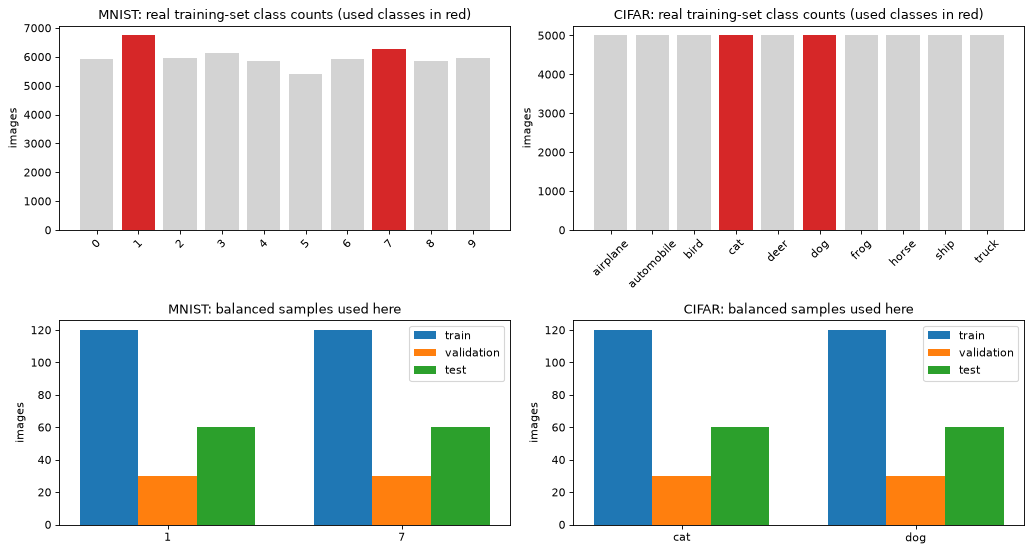

In [7]:
# ---- class distribution of the real datasets (top) and of the balanced samples the models see (bottom) ----
fig, axs = plt.subplots(2, 2, figsize=(13, 7))
for j, name in enumerate(("mnist", "cifar")):
    t, cnt = TASKS[name], FULL_COUNTS[name]
    cols = ["tab:red" if c in t["classes"] else "lightgray" for c in cnt["label"]]
    axs[0, j].bar(cnt["name"], cnt["train"], color=cols)
    axs[0, j].set_title(f"{name.upper()}: real training-set class counts (used classes in red)")
    axs[0, j].tick_params(axis="x", rotation=45); axs[0, j].set_ylabel("images")
    names = [LABEL_NAMES[name][c] for c in t["classes"]]
    w = 0.25
    for off, (lab, y) in enumerate((("train", t["ytr"]), ("validation", t["yva"]), ("test", t["yte"]))):
        axs[1, j].bar(np.arange(2) + (off - 1) * w, np.bincount(y.numpy(), minlength=2), width=w, label=lab)
    axs[1, j].set_xticks(range(2)); axs[1, j].set_xticklabels(names)
    axs[1, j].set_title(f"{name.upper()}: balanced samples used here"); axs[1, j].set_ylabel("images"); axs[1, j].legend()
plt.tight_layout(); plt.show()


### Example images

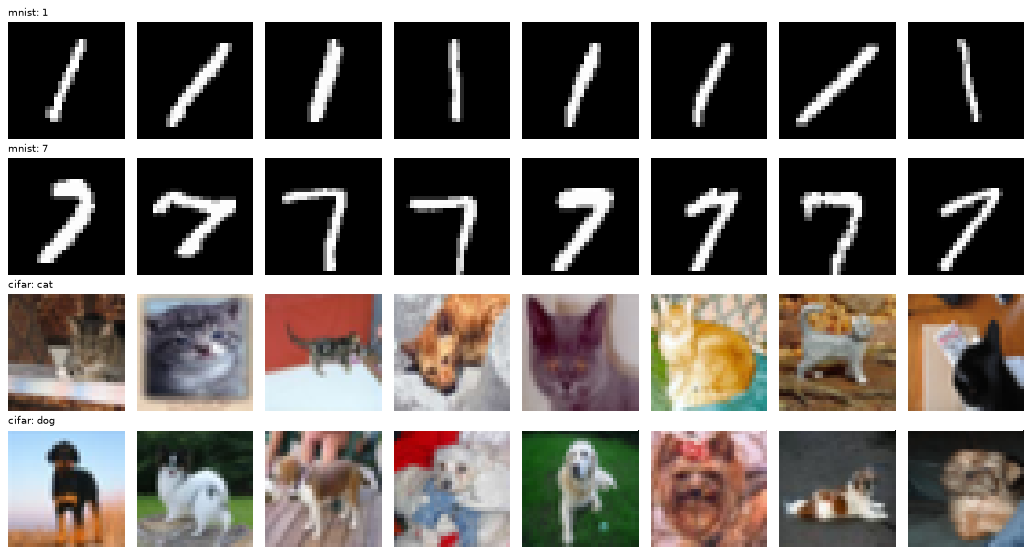

In [8]:
# ---- real example images of the two classes of each task ----
fig, axs = plt.subplots(4, 8, figsize=(13, 7))
for r, name in enumerate(("mnist", "cifar")):
    t = TASKS[name]
    for k in range(2):
        idx = np.where(t["ytr"].numpy() == k)[0][:8]
        for q, i in enumerate(idx):
            im = t["Xtr"][i].permute(1, 2, 0).numpy()
            ax = axs[2 * r + k, q]
            ax.imshow(im[..., 0] if im.shape[2] == 1 else im, cmap="gray" if im.shape[2] == 1 else None, vmin=0, vmax=1)
            ax.axis("off")
            if q == 0:
                ax.set_title(f"{name}: {LABEL_NAMES[name][t['classes'][k]]}", fontsize=9, loc="left")
plt.tight_layout(); plt.show()


### 2-D projections of the real images

Four views per dataset. (a) All ten original classes in the plane of the first two principal components of the raw pixels, to show the
multi-class structure of the real data (60 training images per class). (b) The two classes of the task, PCA fitted on the training split.
(c) The same images as the QCNN sees them (64 unit-norm amplitudes). (d) The QRNN angle sequences: PCA fitted on the training split, then
scaled to $[0, \pi]$ with a scaler fitted on the training split, which is the range of the rotation angles that the angle encoding uses.
The cat/dog classes overlap almost completely in every view, which is the visual counterpart of the low CIFAR-10 accuracies; the digits 1 and 7
separate well.


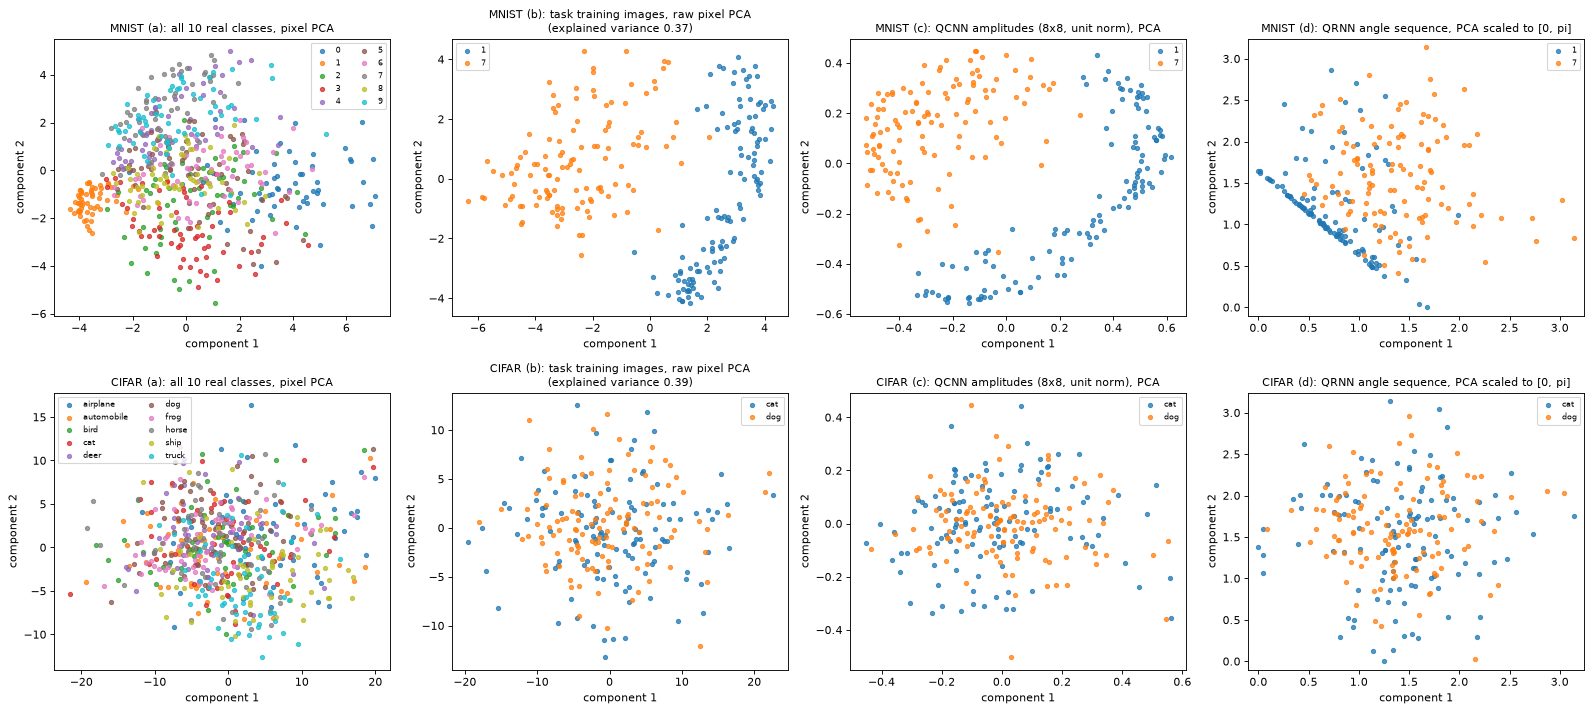

In [9]:
# ---- 2-D scatter plots of REAL observations coloured by their ground-truth label ----
# Row per dataset. (a) all ten original classes (PCA fitted on 60 training images per class);
# (b) the task's training images, raw PCA coordinates fitted on the training split;
# (c) QCNN input (64 amplitudes) PCA; (d) QRNN angles: PCA coordinates scaled to [0, pi] with a scaler fitted on the training split.
def pca_scatter(ax, Z, y, names, title, markers=None, legend=True):
    cmap = plt.get_cmap("tab10")
    for k, nm in enumerate(names):
        m = y == k
        ax.scatter(Z[m, 0], Z[m, 1], s=14, color=cmap(k), alpha=0.75, label=nm)
    ax.set_title(title, fontsize=10); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
    if legend: ax.legend(fontsize=7, ncol=2 if len(names) > 3 else 1)

fig, axs = plt.subplots(2, 4, figsize=(20, 9))
for r, name in enumerate(("mnist", "cifar")):
    t = TASKS[name]; tr = t["train_split"]
    # (a) ten real classes
    r10 = np.random.default_rng(SEED)
    ids = np.concatenate([r10.choice(np.where(tr.labels == c)[0], 60, replace=False) for c in range(10)])
    X10 = torch.tensor(to_chw([tr.get(i) for i in ids])).flatten(1).numpy(); y10 = tr.labels[ids]
    Z10 = PCA(2, random_state=SEED).fit_transform(X10)
    pca_scatter(axs[r, 0], Z10, y10, LABEL_NAMES[name], f"{name.upper()} (a): all 10 real classes, pixel PCA")
    # (b) task images, raw PCA fitted on the training split
    pca = PCA(2, random_state=SEED).fit(t["Xtr"].flatten(1).numpy())
    names2 = [LABEL_NAMES[name][c] for c in t["classes"]]
    pca_scatter(axs[r, 1], pca.transform(t["Xtr"].flatten(1).numpy()), t["ytr"].numpy(), names2,
                f"{name.upper()} (b): task training images, raw pixel PCA\n(explained variance {pca.explained_variance_ratio_.sum():.2f})")
    # (c) QCNN input
    A = qcnn_input(t["Xtr"]).numpy(); pa = PCA(2, random_state=SEED).fit(A)
    pca_scatter(axs[r, 2], pa.transform(A), t["ytr"].numpy(), names2, f"{name.upper()} (c): QCNN amplitudes (8x8, unit norm), PCA")
    # (d) QRNN angles, PCA -> [0, pi]
    ang = qrnn_angles(t["Xtr"], QRNN_GRID[name]).numpy(); pq = PCA(2, random_state=SEED).fit(ang)
    Zq = pq.transform(ang); mm = MinMaxScaler((0, math.pi)).fit(Zq); Zq = mm.transform(Zq)
    pca_scatter(axs[r, 3], Zq, t["ytr"].numpy(), names2, f"{name.upper()} (d): QRNN angle sequence, PCA scaled to [0, pi]")
    axs[r, 3].set_xlim(-0.1, math.pi + 0.1); axs[r, 3].set_ylim(-0.1, math.pi + 0.1)
plt.tight_layout(); plt.show()


## 3. The three quantum models

The three networks are written in PennyLane with the PyTorch interface and exact back-propagation through the simulator, so that Adam can train
them and so that the adversarial attacks can differentiate through the quantum circuits to the input pixels. All parameters are `float64`.

* **QCNN**: amplitude encoding, U3 + Ising convolution, controlled-U3 pooling, final arbitrary unitary on two qubits, output $\langle Z\rangle$.
* **QRNN**: one qubit per time step, shared recurrent ansatz on two memory qubits and the current encoding qubit, output $\langle \sum Z\rangle$.
* **QViT**: classical patch embedding and feed-forward layers around quantum self-attention layers built from 5-qubit circuits.

All three return the **logit** of class 1; the probability is the sigmoid of it. For the QCNN the logit is $\log\frac{P(1)}{P(0)}$ with
$P(1) = (1 - \langle Z\rangle)/2$.


In [10]:
# ================= Model 1: QCNN (6 qubits, amplitude encoding, inverse-MERA style) =================
# Convolution layer : U3 on every qubit, then IsingXX, IsingYY and IsingZZ (shared angles) on neighbouring pairs   (paper Sec. 4.1 / 5.2)
# Pooling layer     : half of the qubits are 'measured'; the outcome controls a U3 on the neighbouring qubit        (paper Sec. 5.2)
# Fully connected   : ArbitraryUnitary on the last two qubits; the output is <Z> of the last qubit
# CHOICE: the measurement-controlled U3 is written as a controlled-U3 (deferred-measurement principle, checked numerically below)
#         because a controlled gate stays differentiable and batchable in PyTorch. Two conv-pool blocks: 6 -> 3 -> 2 qubits.
def qcnn_conv(w, wires):
    for k, q in enumerate(wires):
        qml.U3(w[3 * k], w[3 * k + 1], w[3 * k + 2], wires=q)
    o = 3 * len(wires)
    for a, b in zip(wires[:-1], wires[1:]):
        qml.IsingXX(w[o], wires=[a, b]); qml.IsingYY(w[o + 1], wires=[a, b]); qml.IsingZZ(w[o + 2], wires=[a, b])

def qcnn_pool(w, measured, targets):
    for m, t_ in zip(measured, targets):
        qml.ctrl(qml.U3, control=m)(w[0], w[1], w[2], wires=t_)

def qcnn_body(x, w1, p1, w2, p2, wf, noise=None):
    qml.StatePrep(x, wires=range(6))                   # amplitude encoding of the 8x8 image
    qcnn_conv(w1, [0, 1, 2, 3, 4, 5])
    if noise: [noise(q) for q in range(6)]
    qcnn_pool(p1, [0, 2, 4], [1, 3, 5])
    qcnn_conv(w2, [1, 3, 5])
    if noise: [noise(q) for q in (1, 3, 5)]
    qcnn_pool(p2, [1], [3])
    qml.ArbitraryUnitary(wf, wires=[3, 5])
    return qml.expval(qml.Z(5))

dev_qcnn = qml.device("default.qubit", wires=6)
qcnn_node = qml.QNode(qcnn_body, dev_qcnn, interface="torch", diff_method="backprop")

class QCNN(nn.Module):
    name = "QCNN"
    def __init__(self, task):
        super().__init__()
        u = lambda n: nn.Parameter(torch.rand(n) * 2 * math.pi)     # CHOICE: uniform [0, 2 pi) initial angles
        self.w1, self.p1, self.w2, self.p2, self.wf = u(21), u(3), u(12), u(3), u(15)
    def encode(self, x):                                              # the amplitude vector that StatePrep loads
        return qcnn_input(x)
    def forward(self, x):
        z = qcnn_node(self.encode(x), self.w1, self.p1, self.w2, self.p2, self.wf).clamp(-1 + 1e-7, 1 - 1e-7)
        return -2 * torch.atanh(z)                                    # logit of P(class 1) = (1 - <Z>) / 2
    def fidelity(self, x, xa):                                        # |<psi(x_adv)|psi(x)>|^2, Eq. 22 of the paper
        return (self.encode(x) * self.encode(xa)).sum(1) ** 2
    def features(self, x):                                            # the classical baselines see the same 64 numbers
        return self.encode(x).detach().numpy()

# a PyTorch-friendly handle on the circuit parameters for drawing
def qcnn_args(m, x1):
    return (m.encode(x1)[0], m.w1, m.p1, m.w2, m.p2, m.wf)


In [11]:
# ================= Model 2: QRNN (staggered recurrent block, angle encoding) =================
# One region mean per time step is loaded into a FRESH encoding qubit with RY(pi * s). The memory qubits (n_a = QRNN_MEMORY_QUBITS) and
# the fresh qubit then receive RX-RZ-RX rotations and QRNN_DEPTH blocks of IsingZZ(theta) + RY(theta) (the same parameters at every step,
# as in a recurrent network). A used encoding qubit is never touched again, i.e. it is discarded (traced out). The observable is
# O = sum_j Z_j over the memory qubits and the last encoding qubit, and the prediction is sigmoid(<O>) trained with binary cross-entropy.
#
# Two equivalent simulations of the same circuit are used (equivalence is asserted further below):
#   * 'unrolled'  : n_a + T physical qubits (8 for MNIST, 12 for CIFAR-10), exactly the qubit counts of the paper.
#   * 'windowed'  : n_a + 1 = 3 physical wires on the density-matrix simulator; 'a fresh qubit' is implemented as a reset to |0>
#                   (ResetError with probability 1). Same unitary dynamics, same measurement, but ~10x cheaper on a CPU.
# The windowed version is the one trained and attacked below; the unrolled one is drawn and used as the reference.
NA = QRNN_MEMORY_QUBITS

def qrnn_ansatz(rot, zz, ry, act):
    for k, q in enumerate(act):
        qml.RX(rot[k, 0], wires=q); qml.RZ(rot[k, 1], wires=q); qml.RX(rot[k, 2], wires=q)
    for d in range(zz.shape[0]):
        for j, (a, b) in enumerate(zip(act[:-1], act[1:])):
            qml.IsingZZ(zz[d, j], wires=[a, b])
        for k, q in enumerate(act):
            qml.RY(ry[d, k], wires=q)

def qrnn_windowed_body(seq, rot, zz, ry, noise=None, probs=False):
    act = list(range(NA + 1)); w = NA
    for t in range(seq.shape[-1]):
        if t > 0:
            qml.ResetError(1.0, 0.0, wires=w)                      # discard the used encoding qubit, bring in a fresh |0>
        qml.RY(math.pi * seq[:, t] if seq.ndim == 2 else math.pi * seq[t], wires=w)
        qrnn_ansatz(rot, zz, ry, act)
        if noise: [noise(q) for q in act]
    if probs:
        return qml.probs(wires=act)
    return qml.expval(sum(qml.Z(q) for q in act[1:]) + qml.Z(0))

def make_unrolled_node(T):
    dev = qml.device("default.qubit", wires=NA + T)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def unrolled(seq, rot, zz, ry):
        for t in range(T):
            w = NA + t; act = list(range(NA)) + [w]
            qml.RY(math.pi * seq[:, t] if seq.ndim == 2 else math.pi * seq[t], wires=w)
            qrnn_ansatz(rot, zz, ry, act)
        return qml.expval(sum(qml.Z(q) for q in range(NA)) + qml.Z(NA + T - 1))
    return unrolled

dev_qrnn = qml.device("default.mixed", wires=NA + 1)
qrnn_node = qml.QNode(qrnn_windowed_body, dev_qrnn, interface="torch", diff_method="backprop")

class QRNN(nn.Module):
    name = "QRNN"
    def __init__(self, task):
        super().__init__()
        self.grid = QRNN_GRID[task]
        u = lambda *s: nn.Parameter((torch.rand(*s) * 2 - 1) * QRNN_INIT)   # paper Alg. 2: theta ~ U(-pi, pi); QRNN_INIT = pi follows it
        self.rot, self.zz, self.ry = u(NA + 1, 3), u(QRNN_DEPTH, NA), u(QRNN_DEPTH, NA + 1)
        # CHOICE: two classical read-out parameters (gain and bias). <O> lies in [-3, 3]; with sigmoid(<O>) alone the loss cannot
        #         fall below about 0.05 and, in practice, training is very slow. The sign of the logit (the decision) is set by <O> + bias / gain.
        self.gain, self.bias = nn.Parameter(torch.tensor(2.0)), nn.Parameter(torch.tensor(0.0))
    def seq(self, x):
        return qrnn_sequence(x, self.grid)
    def forward(self, x):
        return self.gain * qrnn_node(self.seq(x), self.rot, self.zz, self.ry) + self.bias   # logit of P(class 1)
    def fidelity(self, x, xa):                                          # product of single-qubit overlaps cos^2((a - b) / 2)
        return torch.cos(math.pi * (self.seq(x) - self.seq(xa)) / 2).pow(2).prod(1)
    def features(self, x):
        return self.seq(x).detach().numpy()


In [12]:
# ================= Model 3: QViT (quantum self-attention layers, 5 qubits, amplitude encoding) =================
# Classical part (as in a vision transformer): patch embedding -> + positional encoding -> [LayerNorm -> QSAL -> residual -> LayerNorm
# -> feed-forward -> residual] x L -> LayerNorm -> flatten -> linear logit.
# Quantum part (QSAL, Li et al. 2024 QSANN, paper Alg. 3): each patch embedding is split into d_model/32 chunks of 32 numbers; every chunk
# is amplitude-encoded on 5 qubits. Three parameterised circuits U_Q, U_K, U_V follow; Q and K give <Z_0>, V gives the expectation values of
# X, Y, Z on every qubit (15 numbers). Gaussian-projected attention: alpha_ij ~ exp(-(q_i - k_j)^2), normalised over j.
# CHOICE: ansatz = 2 blocks of [RX, RY on every qubit, CNOT brick (0-1, 2-3), CNOT brick (1-2, 3-4)] -> depth 8 after state preparation
#         (paper: '5 qubits and a circuit depth of 8'); the V output (15 values per head) is mapped back to d_model by a linear layer.
def qsal_ansatz(w):
    for b in range(2):
        for q in range(5):
            qml.RX(w[b, q, 0], wires=q); qml.RY(w[b, q, 1], wires=q)
        qml.CNOT(wires=[0, 1]); qml.CNOT(wires=[2, 3])
        qml.CNOT(wires=[1, 2]); qml.CNOT(wires=[3, 4])

dev_qvit = qml.device("default.qubit", wires=5)

@qml.qnode(dev_qvit, interface="torch", diff_method="backprop")
def qsal_qk(x, w):                                   # query / key circuit: one expectation value
    qml.StatePrep(x, wires=range(5)); qsal_ansatz(w)
    return qml.expval(qml.Z(0))

@qml.qnode(dev_qvit, interface="torch", diff_method="backprop")
def qsal_v(x, w):                                    # value circuit: 15 Pauli expectation values
    qml.StatePrep(x, wires=range(5)); qsal_ansatz(w)
    return [qml.expval(P(q)) for P in (qml.X, qml.Y, qml.Z) for q in range(5)]

class QSALayer(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        qw = lambda: nn.Parameter((torch.rand(2, 5, 2) * 2 - 1) * math.pi)
        self.wq, self.wk, self.wv = qw(), qw(), qw()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.proj = nn.Linear(15 * heads, d)
        self.ffn = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
        self.heads = heads
    def forward(self, z):
        B, S, d = z.shape; H = self.heads
        h = self.ln1(z).reshape(B * S * H, 32)
        h = h / h.norm(dim=1, keepdim=True)                                # unit-norm amplitudes for StatePrep
        q = qsal_qk(h, self.wq).reshape(B, S, H); k = qsal_qk(h, self.wk).reshape(B, S, H)
        v = torch.stack(qsal_v(h, self.wv), dim=-1).reshape(B, S, H, 15)
        att = torch.exp(-(q[:, :, None, :] - k[:, None, :, :]) ** 2)        # (B, i, j, H) Gaussian-projected similarity
        att = att / att.sum(2, keepdim=True)
        o = torch.einsum("bijh,bjhc->bihc", att, v).reshape(B, S, H * 15)
        z = z + self.proj(o)                                               # residual connection
        return z + self.ffn(self.ln2(z))

class QViT(nn.Module):
    name = "QViT"
    def __init__(self, task):
        super().__init__()
        c, img = (1, 28) if task == "mnist" else (3, 32)
        self.p, d = QVIT_PATCH[task], QVIT_DMODEL[task]
        self.S = (img // self.p) ** 2
        self.embed = nn.Linear(c * self.p * self.p, d)
        self.pos = nn.Parameter(0.02 * torch.randn(self.S, d))
        self.layers = nn.ModuleList([QSALayer(d, d // 32) for _ in range(QVIT_LAYERS[task])])
        self.lnf = nn.LayerNorm(d); self.head = nn.Linear(self.S * d, 1)
    def tokens(self, x):
        return self.embed(patchify(x, self.p)) + self.pos
    def forward(self, x):
        z = self.tokens(x)
        for L in self.layers:
            z = L(z)
        return self.head(self.lnf(z).flatten(1)).squeeze(-1)
    def encode(self, x):                                                   # states loaded by the first QSAL: (B, S*heads, 32)
        h = self.layers[0].ln1(self.tokens(x)).reshape(x.shape[0], -1, 32)
        return h / h.norm(dim=2, keepdim=True)
    def fidelity(self, x, xa):                                             # mean over the encoded patch-chunks
        return ((self.encode(x) * self.encode(xa)).sum(2) ** 2).mean(1)
    def features(self, x):
        return x.flatten(1).numpy()

MODELS = {"QCNN": QCNN, "QRNN": QRNN, "QViT": QViT}
def n_params(m, quantum_only=False):
    tot = sum(p.numel() for p in m.parameters())
    if not quantum_only:
        return tot
    qnames = ("w1", "p1", "w2", "p2", "wf", "rot", "zz", "ry", "wq", "wk", "wv")
    return sum(p.numel() for n, p in m.named_parameters() if n.split(".")[-1] in qnames)

for tk in ("mnist", "cifar"):
    torch.manual_seed(SEED)
    row = {k: (n_params(MODELS[k](tk)), n_params(MODELS[k](tk), True)) for k in MODELS}
    print(tk, "(total trainable, of which quantum-circuit parameters):", row)


mnist (total trainable, of which quantum-circuit parameters): {'QCNN': (54, 54), 'QRNN': (21, 19), 'QViT': (7581, 60)}
cifar (total trainable, of which quantum-circuit parameters): {'QCNN': (54, 54), 'QRNN': (21, 19), 'QViT': (17049, 120)}


## Quantum Circuit Architecture

The drawings below are produced by `qml.draw_mpl` on the very QNodes that are trained and attacked. For each architecture the code prints the
number of qubits, the gate count and depth, and the number of trainable circuit parameters.

* **QCNN**: one drawing (same circuit for MNIST and CIFAR-10): StatePrep (amplitude encoding of the 8x8 image), convolution layer on six qubits,
  pooling by controlled U3 (qubits 0, 2, 4 control 1, 3, 5), convolution on qubits 1, 3, 5, pooling (qubit 1 controls qubit 3), arbitrary unitary on
  qubits 3 and 5, measurement of qubit 5. A check cell shows that the controlled gate gives exactly the same output as a mid-circuit measurement
  followed by a classically conditioned U3.
* **QRNN**: the executed circuit uses three wires and a reset between time steps; the second drawing is the unrolled eight-qubit circuit that the
  paper describes. An assertion shows that both give the same outputs to 1e-8 on real MNIST (8 qubits) and CIFAR-10 (12 qubits) images.
* **QViT**: the quantum self-attention layer contains two distinct architectures, the query/key circuit (one expectation value) and the value
  circuit (fifteen expectation values). Both are drawn; one network contains 3 x (d_model / 32) x layers copies with their own weights.

Assumptions where the paper is silent: the QCNN parameter sharing; the QRNN split into memory and encoding qubits and the observable; the QViT
ansatz, the number of heads and the value observables. They are listed in the table "What follows the paper and what had to be chosen".


In [13]:
def circuit_stats(node, args, kwargs=None, label="", n_trainable=None):
    sp = qml.specs(node, level="top")(*args, **(kwargs or {}))
    res = sp["resources"]
    sp_dev = qml.specs(node, level="device")(*args, **(kwargs or {}))
    print(f"{label}: qubits used = {res.num_allocs} | gates at the top level = {res.num_gates}, depth = {res.depth} | "
          f"after device decomposition: gates = {sp_dev['resources'].num_gates}, depth = {sp_dev['resources'].depth} | "
          f"trainable circuit parameters = {n_trainable}")
    return res

def show(fig_ax):
    fig, ax = fig_ax
    plt.show()


Matplotlib is building the font cache; this may take a moment.


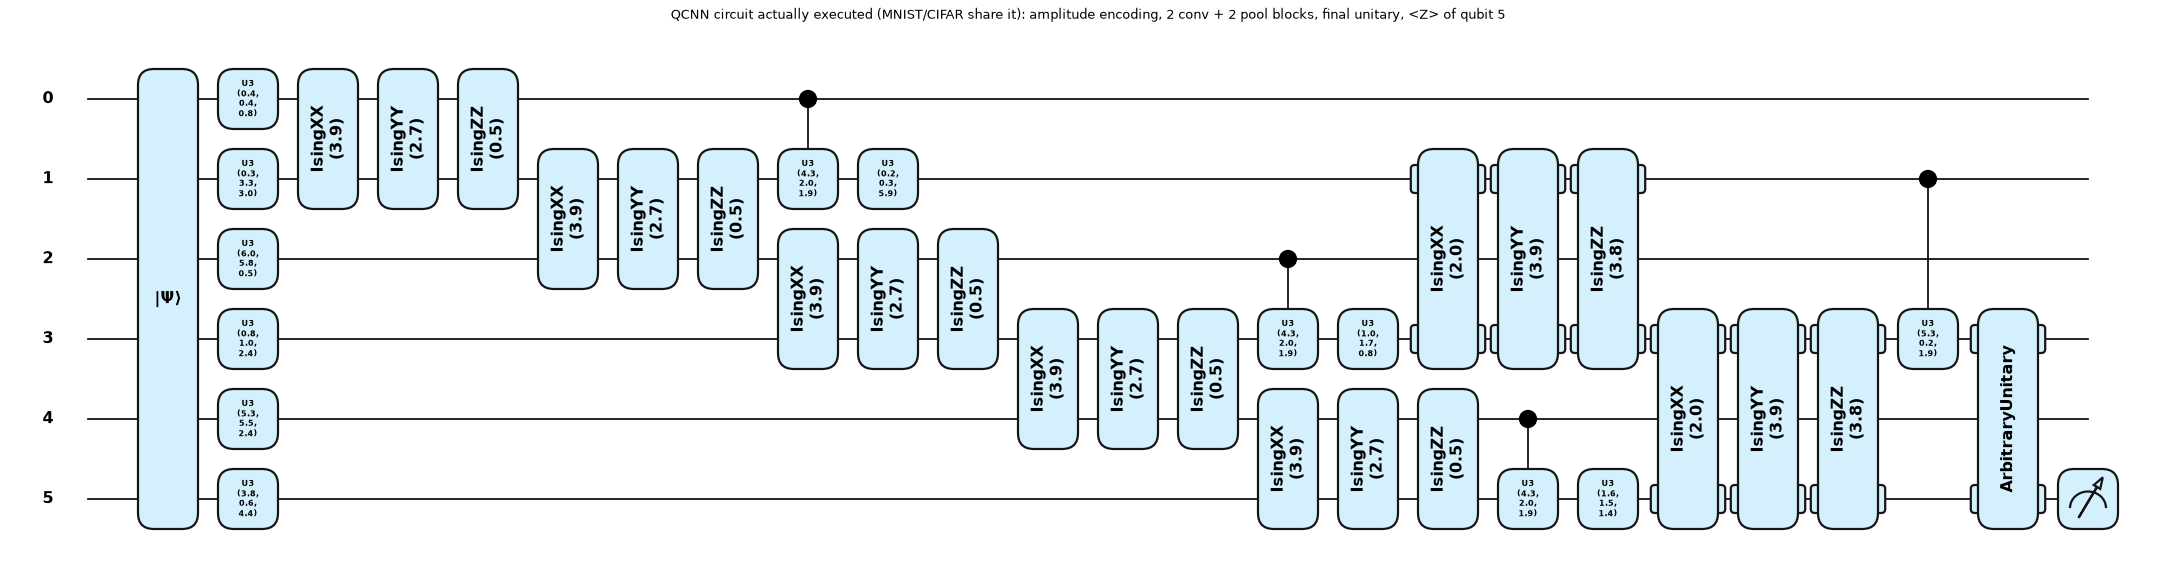

QCNN: qubits used = 6 | gates at the top level = 36, depth = 24 | after device decomposition: gates = 50, depth = 38 | trainable circuit parameters = 54


controlled-U3 pooling: 0.031912179201055935 | measurement + conditional U3: 0.031912179201055935


In [14]:
torch.manual_seed(SEED)
m_demo = QCNN("mnist")
x1 = TASKS["mnist"]["Xte"][:1]
args = qcnn_args(m_demo, x1)
fig, ax = qml.draw_mpl(qcnn_node, decimals=1, style="pennylane")(*args)
fig.suptitle("QCNN circuit actually executed (MNIST/CIFAR share it): amplitude encoding, 2 conv + 2 pool blocks, final unitary, <Z> of qubit 5", y=1.02)
plt.show()
circuit_stats(qcnn_node, args, label="QCNN", n_trainable=n_params(m_demo, True))

# ---- check: controlled-U3 pooling == mid-circuit measurement + conditional U3 (deferred measurement principle) ----
dev_chk = qml.device("default.qubit", wires=6)
def qcnn_with_measure(x, w1, p1, w2, p2, wf):
    qml.StatePrep(x, wires=range(6)); qcnn_conv(w1, [0, 1, 2, 3, 4, 5])
    for m_, t_ in zip([0, 2, 4], [1, 3, 5]):
        mv = qml.measure(m_); qml.cond(mv, qml.U3)(p1[0], p1[1], p1[2], wires=t_)
    qcnn_conv(w2, [1, 3, 5])
    mv = qml.measure(1); qml.cond(mv, qml.U3)(p2[0], p2[1], p2[2], wires=3)
    qml.ArbitraryUnitary(wf, wires=[3, 5])
    return qml.expval(qml.Z(5))
chk = qml.QNode(qcnn_with_measure, dev_chk, interface="torch")
with torch.no_grad():
    a = qcnn_node(*args); b = chk(*args)
print("controlled-U3 pooling:", float(a), "| measurement + conditional U3:", float(b))
assert abs(float(a) - float(b)) < 1e-9, "pooling implementations differ"


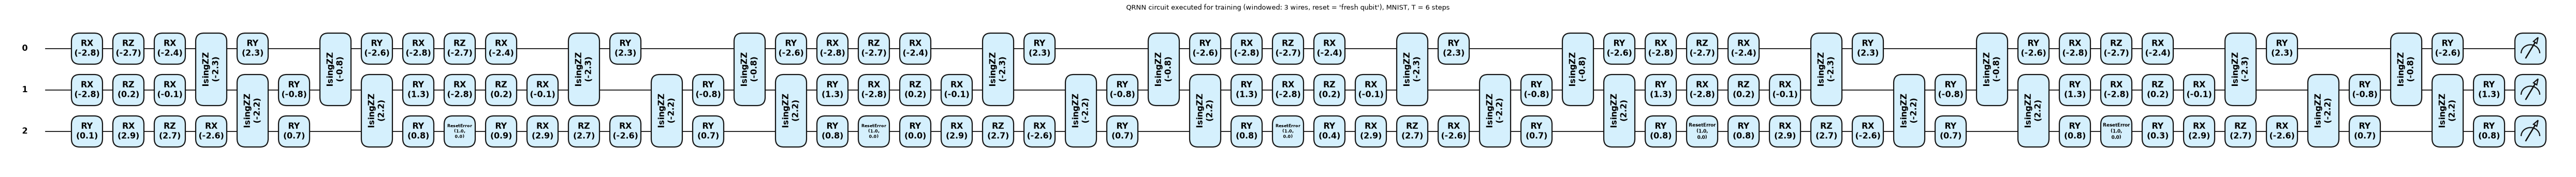

QRNN windowed MNIST: qubits used = 3 | gates at the top level = 125, depth = 59 | after device decomposition: gates = 173, depth = 102 | trainable circuit parameters = 19


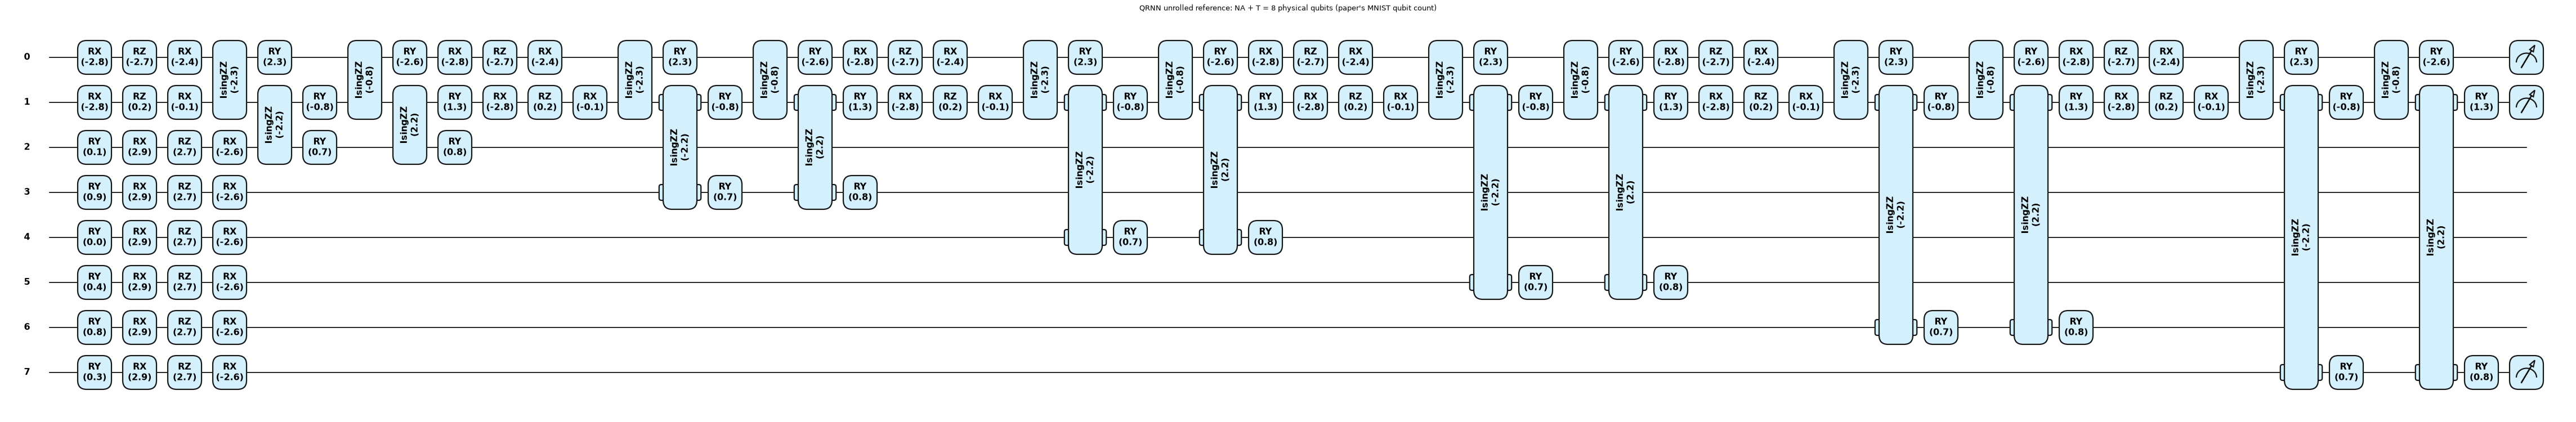

QRNN unrolled MNIST: qubits used = 8 | gates at the top level = 120, depth = 54 | after device decomposition: gates = 120, depth = 54 | trainable circuit parameters = 19


mnist: 8 qubits unrolled vs 3 wires windowed, max |difference| over 4 real images = 1.35e-13


cifar: 12 qubits unrolled vs 3 wires windowed, max |difference| over 4 real images = 2.21e-13


In [15]:
# ---- QRNN: the executed (windowed) circuit and the 8-qubit unrolled reference ----
torch.manual_seed(SEED)
q_m = QRNN("mnist"); q_c = QRNN("cifar")
seq_m = q_m.seq(TASKS["mnist"]["Xte"][:1])[0]                    # one real test image -> its 6-step sequence
fig, ax = qml.draw_mpl(qrnn_node, decimals=1, style="pennylane")(seq_m, q_m.rot, q_m.zz, q_m.ry)
fig.suptitle("QRNN circuit executed for training (windowed: 3 wires, reset = 'fresh qubit'), MNIST, T = 6 steps", y=1.02)
plt.show()
circuit_stats(qrnn_node, (seq_m, q_m.rot, q_m.zz, q_m.ry), label="QRNN windowed MNIST", n_trainable=n_params(q_m, True))

unr_m = make_unrolled_node(seq_m.shape[0])
fig, ax = qml.draw_mpl(unr_m, decimals=1, style="pennylane")(seq_m, q_m.rot, q_m.zz, q_m.ry)
fig.suptitle("QRNN unrolled reference: NA + T = 8 physical qubits (paper's MNIST qubit count)", y=1.02)
plt.show()
circuit_stats(unr_m, (seq_m, q_m.rot, q_m.zz, q_m.ry), label="QRNN unrolled MNIST", n_trainable=n_params(q_m, True))

# ---- equivalence of windowed and unrolled circuits on real test images, MNIST (8 qubits) and CIFAR-10 (12 qubits) ----
for tk, mdl in (("mnist", q_m), ("cifar", q_c)):
    s = mdl.seq(TASKS[tk]["Xte"][:4])
    unr = make_unrolled_node(s.shape[1])
    with torch.no_grad():
        a, b = qrnn_node(s, mdl.rot, mdl.zz, mdl.ry), unr(s, mdl.rot, mdl.zz, mdl.ry)
    print(f"{tk}: {NA + s.shape[1]} qubits unrolled vs 3 wires windowed, max |difference| over 4 real images = {float((a - b).abs().max()):.2e}")
    assert torch.allclose(a, b, atol=1e-8)


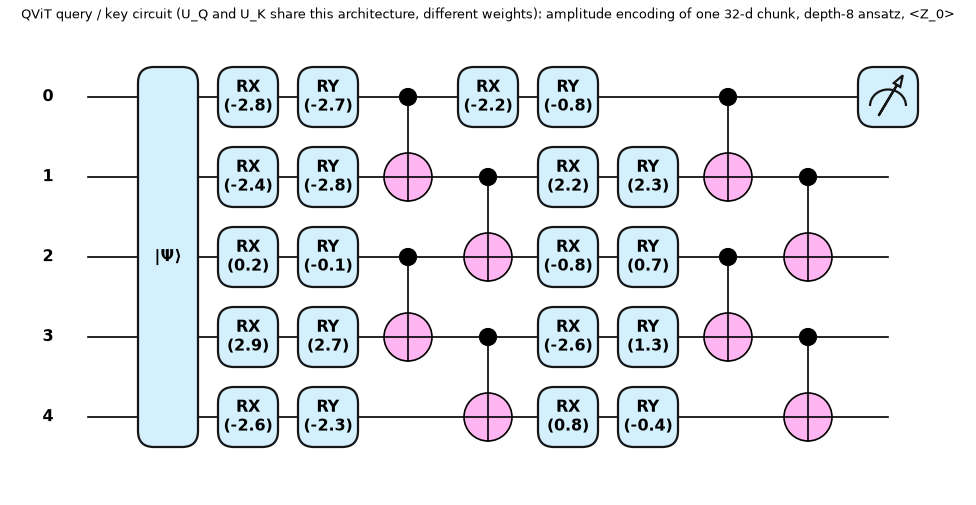

QSAL query/key circuit: qubits used = 5 | gates at the top level = 29, depth = 9 | after device decomposition: gates = 29, depth = 9 | trainable circuit parameters = 20


Matplotlib is building the font cache; this may take a moment.


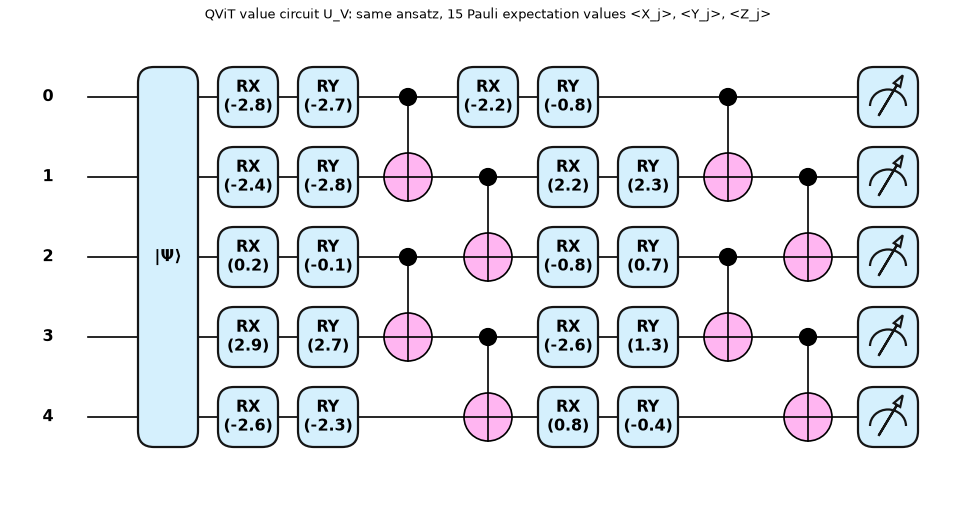

QSAL value circuit: qubits used = 5 | gates at the top level = 29, depth = 9 | after device decomposition: gates = 29, depth = 9 | trainable circuit parameters = 20
QViT mnist: 1 QSAL layer(s) x 1 head(s) x 3 circuits (Q,K,V) on 5 qubits; 60 circuit parameters out of 7581 trainable parameters in total (the rest is the classical transformer part).
QViT cifar: 2 QSAL layer(s) x 1 head(s) x 3 circuits (Q,K,V) on 5 qubits; 120 circuit parameters out of 17049 trainable parameters in total (the rest is the classical transformer part).


In [16]:
torch.manual_seed(SEED)
w_demo = (torch.rand(2, 5, 2) * 2 - 1) * math.pi
x32 = F.normalize(torch.randn(32), dim=0)
fig, ax = qml.draw_mpl(qsal_qk, decimals=1, style="pennylane")(x32, w_demo)
fig.suptitle("QViT query / key circuit (U_Q and U_K share this architecture, different weights): amplitude encoding of one 32-d chunk, depth-8 ansatz, <Z_0>", y=1.02)
plt.show()
circuit_stats(qsal_qk, (x32, w_demo), label="QSAL query/key circuit", n_trainable=w_demo.numel())
fig, ax = qml.draw_mpl(qsal_v, decimals=1, style="pennylane")(x32, w_demo)
fig.suptitle("QViT value circuit U_V: same ansatz, 15 Pauli expectation values <X_j>, <Y_j>, <Z_j>", y=1.02)
plt.show()
circuit_stats(qsal_v, (x32, w_demo), label="QSAL value circuit", n_trainable=w_demo.numel())
for tk in ("mnist", "cifar"):
    mv = QViT(tk)
    nq = sum(p.numel() for n, p in mv.named_parameters() if n.split(".")[-1] in ("wq", "wk", "wv"))
    print(f"QViT {tk}: {len(mv.layers)} QSAL layer(s) x {QVIT_DMODEL[tk] // 32} head(s) x 3 circuits (Q,K,V) on 5 qubits; "
          f"{nq} circuit parameters out of {n_params(mv)} trainable parameters in total (the rest is the classical transformer part).")


## 4. Training the three networks (paper Table 1)

Every model is trained with Adam and binary cross-entropy. After each epoch the validation loss is computed and the best epoch is kept. The table
reports test accuracy and loss, the training loss, and the generalisation gap $|L_{test} - L_{train}|$ that stands in for the paper's
"generalization bound". With `N_REPEATS > 1` the numbers are means over independent initialisations and data orders.


In [17]:
# ---- training and evaluation helpers ----
def predict_logits(model, X, bs=128):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(model(X[i:i + bs]))
    return torch.cat(out)

def bce(z, y):
    return F.binary_cross_entropy_with_logits(z, y.double())

def evaluate(model, X, y):
    z = predict_logits(model, X)
    return dict(acc=float(((z > 0).long() == y).double().mean()), loss=float(bce(z, y)))

def train_model(model, Xtr, ytr, Xva, yva, epochs, lr, seed, bs=None, cosine=True, tag="", log_every=5):
    """Adam (paper Alg. 1-3), cosine learning-rate decay for QRNN/QViT (paper Alg. 2-3), binary cross-entropy.
    The epoch with the lowest validation loss is kept (validation split only; the test split is never used for model selection)."""
    bs = bs or 32
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if cosine else None
    gen = torch.Generator().manual_seed(seed)
    hist = dict(train=[], val=[], val_acc=[]); best = (1e9, None); t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), generator=gen); tot = 0.0
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]
            opt.zero_grad(); loss = bce(model(Xtr[b]), ytr[b]); loss.backward(); opt.step()
            tot += float(loss) * len(b)
        if sched: sched.step()
        ev = evaluate(model, Xva, yva)
        hist["train"].append(tot / len(Xtr)); hist["val"].append(ev["loss"]); hist["val_acc"].append(ev["acc"])
        if ev["loss"] < best[0]:
            best = (ev["loss"], copy.deepcopy(model.state_dict()))
        if log_every and ((ep + 1) % log_every == 0 or ep == 0):
            print(f"  {tag} epoch {ep + 1:3d}/{epochs}  train loss {hist['train'][-1]:.3f}  val loss {ev['loss']:.3f}  val acc {ev['acc']:.3f}  [{time.time() - t0:.0f} s]")
    model.load_state_dict(best[1]); hist["time"] = time.time() - t0
    return hist


In [18]:
# ---- Experiment 1 (paper Table 1): train the three QNNs on both binary tasks, N_REPEATS independent seeds ----
TRAINED, HIST, ROWS = {}, {}, []
for tk in ("mnist", "cifar"):
    t = TASKS[tk]
    for mname, cls in MODELS.items():
        for r in range(N_REPEATS):
            seed = SEED + 100 * r
            torch.manual_seed(seed)
            model = cls(tk)
            t0 = time.time()
            hist = train_model(model, t["Xtr"], t["ytr"], t["Xva"], t["yva"], EPOCHS[mname], LR[mname], seed, bs=BATCH[mname],
                               cosine=(mname != "QCNN"), tag=f"{mname}/{tk}/seed{seed}", log_every=5 if r == 0 else 0)
            tr_ev, te_ev = evaluate(model, t["Xtr"], t["ytr"]), evaluate(model, t["Xte"], t["yte"])
            ROWS.append(dict(task=tk, model=mname, seed=seed, train_acc=tr_ev["acc"], train_loss=tr_ev["loss"],
                             test_acc=te_ev["acc"], test_loss=te_ev["loss"], gap=abs(te_ev["loss"] - tr_ev["loss"]),
                             seconds=time.time() - t0, params=n_params(model)))
            if r == 0:
                TRAINED[(tk, mname)], HIST[(tk, mname)] = model, hist
RES = pd.DataFrame(ROWS)
print(f"total training time {RES['seconds'].sum() / 60:.1f} min")
display(RES.round(3))


  QCNN/mnist/seed42 epoch   1/25  train loss 0.630  val loss 0.530  val acc 0.917  [6 s]


  QCNN/mnist/seed42 epoch   5/25  train loss 0.413  val loss 0.420  val acc 0.950  [21 s]


  QCNN/mnist/seed42 epoch  10/25  train loss 0.392  val loss 0.386  val acc 0.933  [37 s]


  QCNN/mnist/seed42 epoch  15/25  train loss 0.351  val loss 0.354  val acc 0.933  [54 s]


  QCNN/mnist/seed42 epoch  20/25  train loss 0.331  val loss 0.335  val acc 0.933  [73 s]


...

  QViT/cifar/seed42 epoch   1/10  train loss 1.357  val loss 0.761  val acc 0.500  [38 s]


  QViT/cifar/seed42 epoch   5/10  train loss 0.715  val loss 0.704  val acc 0.500  [158 s]


  QViT/cifar/seed42 epoch  10/10  train loss 0.688  val loss 0.694  val acc 0.517  [466 s]


total training time 25.1 min


,task,model,seed,train_acc,train_loss,test_acc,test_loss,gap,seconds,params
0,mnist,QCNN,42,0.975,0.317,0.967,0.307,0.010,110.878,54
1,mnist,QRNN,42,0.875,0.471,0.908,0.447,0.024,233.951,21
2,mnist,QViT,42,1.000,0.002,0.992,0.061,0.059,97.152,7581
3,cifar,QCNN,42,0.629,0.670,0.633,0.656,0.014,70.164,54
4,cifar,QRNN,42,0.562,0.686,0.592,0.681,0.005,490.132,21
5,cifar,QViT,42,0.533,0.686,0.533,0.687,0.001,501.672,17049


### Loss curves and confusion matrices

The confusion matrices use class 1 (the second class of each pair: digit 7, dog) as the positive class; this is a vision task, there is no
"attack" class. Rows are true classes, columns predictions.


,model,task,acc_mean,acc_std,loss,gen_gap,train_acc,params,seconds
0,QCNN,cifar,0.633,NaN,0.656,0.014,0.629,54,70.164
1,QCNN,mnist,0.967,NaN,0.307,0.010,0.975,54,110.878
2,QRNN,cifar,0.592,NaN,0.681,0.005,0.562,21,490.132
3,QRNN,mnist,0.908,NaN,0.447,0.024,0.875,21,233.951
4,QViT,cifar,0.533,NaN,0.687,0.001,0.533,17049,501.672
5,QViT,mnist,0.992,NaN,0.061,0.059,1.000,7581,97.152


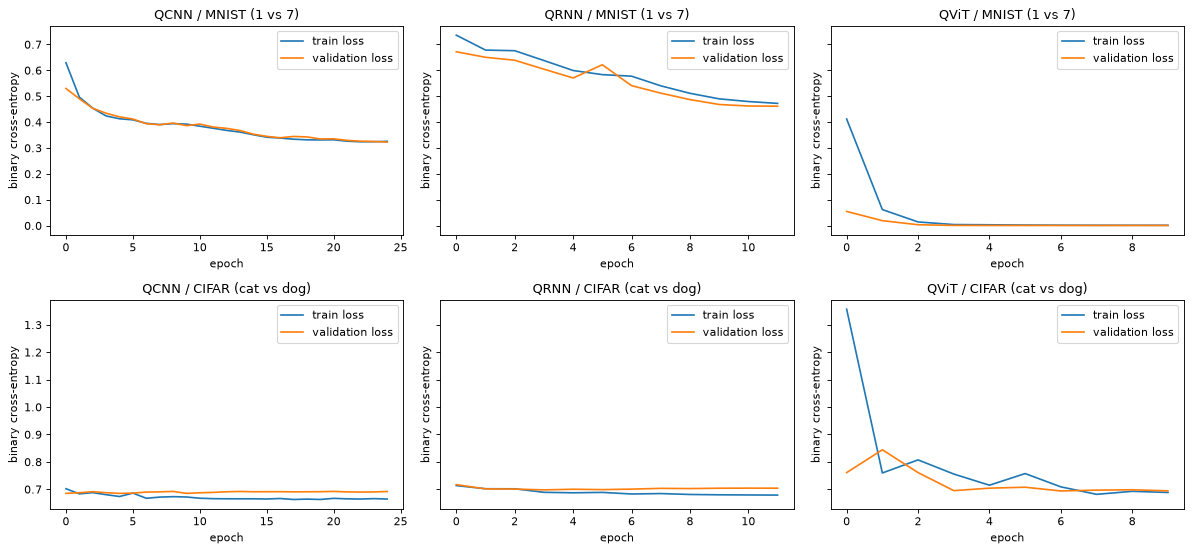

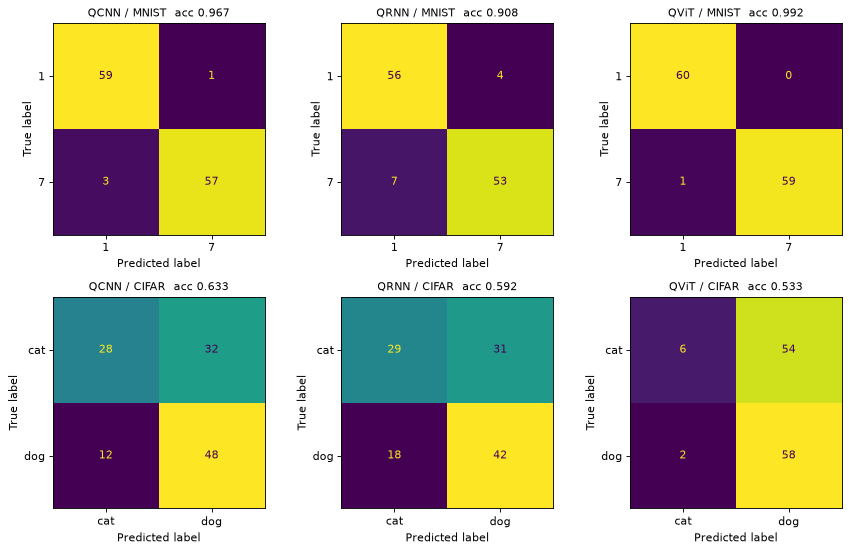

In [19]:
SUMMARY = (RES.groupby(["model", "task"])
              .agg(acc_mean=("test_acc", "mean"), acc_std=("test_acc", "std"), loss=("test_loss", "mean"),
                   gen_gap=("gap", "mean"), train_acc=("train_acc", "mean"), params=("params", "first"), seconds=("seconds", "mean"))
              .round(3).reset_index())
display(SUMMARY)

fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for r_, tk in enumerate(("mnist", "cifar")):
    for c_, mname in enumerate(MODELS):
        h = HIST[(tk, mname)]
        axs[r_, c_].plot(h["train"], label="train loss"); axs[r_, c_].plot(h["val"], label="validation loss")
        axs[r_, c_].set_title(f"{mname} / {tk.upper()} ({'1 vs 7' if tk == 'mnist' else 'cat vs dog'})")
        axs[r_, c_].set_xlabel("epoch"); axs[r_, c_].set_ylabel("binary cross-entropy"); axs[r_, c_].legend()
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 3, figsize=(11, 7))
for r_, tk in enumerate(("mnist", "cifar")):
    for c_, mname in enumerate(MODELS):
        t = TASKS[tk]; z = predict_logits(TRAINED[(tk, mname)], t["Xte"])
        cm = confusion_matrix(t["yte"].numpy(), (z > 0).long().numpy(), labels=[0, 1])
        names = [LABEL_NAMES[tk][c] for c in t["classes"]]
        ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=axs[r_, c_], colorbar=False)
        axs[r_, c_].set_title(f"{mname} / {tk.upper()}  acc {np.trace(cm) / cm.sum():.3f}", fontsize=10)
plt.tight_layout(); plt.show()


### Classical baselines on identical inputs

An SVM with RBF kernel and a random forest are trained on exactly the numbers each quantum model receives (64 amplitudes for the QCNN, the region
sequence for the QRNN, all pixels for the QViT), and a small convolutional network on the full image. The paper states that QCNN is "less
effective on high-dimensional data than other machine learning architectures" but gives no numbers; this table is the check.


In [20]:
# ---- classical baselines on the SAME inputs as each quantum model (7. in the project checklist) ----
class SmallCNN(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(c, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(),
                                 nn.AdaptiveAvgPool2d(4), nn.Flatten(), nn.Linear(256, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

BASE, CNN_MODELS = [], {}
for tk in ("mnist", "cifar"):
    t = TASKS[tk]
    for mname in MODELS:
        m_ = TRAINED[(tk, mname)]
        Ftr, Fte = m_.features(t["Xtr"]), m_.features(t["Xte"])
        for cname, clf in (("SVC rbf", SVC(kernel="rbf", C=1.0, gamma="scale")),
                           ("RandomForest", RandomForestClassifier(n_estimators=100, random_state=SEED))):
            clf.fit(Ftr, t["ytr"].numpy())
            BASE.append(dict(task=tk, quantum_model=mname, input=f"{Ftr.shape[1]} features as seen by {mname}", baseline=cname,
                             test_acc=float((clf.predict(Fte) == t["yte"].numpy()).mean())))
    torch.manual_seed(SEED)
    cnn = SmallCNN(t["Xtr"].shape[1])
    train_model(cnn, t["Xtr"], t["ytr"], t["Xva"], t["yva"], 15 if FAST_MODE else 30, 0.01, SEED, cosine=False, log_every=0)
    CNN_MODELS[tk] = cnn
    BASE.append(dict(task=tk, quantum_model="-", input="full image", baseline="small CNN (classical)",
                     test_acc=evaluate(cnn, t["Xte"], t["yte"])["acc"]))
BASE = pd.DataFrame(BASE)
display(BASE.pivot_table(index=["task", "baseline"], columns="quantum_model", values="test_acc").round(3))
print("Quantum models (test accuracy, seed-0 model):")
print({f"{tk}/{m}": round(evaluate(TRAINED[(tk, m)], TASKS[tk]["Xte"], TASKS[tk]["yte"])["acc"], 3) for tk in TASKS for m in MODELS})


quantum_model                    -   QCNN   QRNN   QViT
task  baseline                                         
cifar RandomForest             NaN  0.717  0.575  0.667
      SVC rbf                  NaN  0.600  0.583  0.633
      small CNN (classical)  0.483    NaN    NaN    NaN
mnist RandomForest             NaN  0.983  0.967  0.992
      SVC rbf                  NaN  0.992  0.967  0.992
      small CNN (classical)  0.992    NaN    NaN    NaN

Quantum models (test accuracy, seed-0 model):


{'mnist/QCNN': 0.967, 'mnist/QRNN': 0.908, 'mnist/QViT': 0.992, 'cifar/QCNN': 0.633, 'cifar/QRNN': 0.592, 'cifar/QViT': 0.533}


## 5. Lipschitz bound (paper Table 2)

The Lipschitz bound measures how fast the output can change when the input moves. Following the text of Sec. 5.4.2 it is computed as the maximum,
over the training images, of the norm of the gradient of the model output with respect to the input image. A large value means a small
perturbation can cause a large change of the output. We use the logit as the output (the paper argues about the pre-softmax logits of the QViT)
and also print the value for the probability, the mean over images, and the $L_1$ norm of the gradient (the dual norm that controls
$L_\infty$ perturbations).


In [21]:
# ---- Experiment 2 (paper Table 2): empirical Lipschitz bound = max over TRAINING images of the norm of the gradient of the model output
#      with respect to the input image (paper Sec. 5.4.2) ----
def lipschitz(model, X, bs=64):
    model.eval(); l2, l2p, l1 = [], [], []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].clone().requires_grad_(True)
        z = model(x)
        g = torch.autograd.grad(z.sum(), x, retain_graph=True)[0].flatten(1)        # gradient of the logit
        gp = torch.autograd.grad(torch.sigmoid(z).sum(), x)[0].flatten(1)          # gradient of the class-1 probability
        l2.append(g.norm(dim=1)); l1.append(g.abs().sum(1)); l2p.append(gp.norm(dim=1))
    l2, l1, l2p = torch.cat(l2), torch.cat(l1), torch.cat(l2p)
    return dict(L2_logit_max=float(l2.max()), L2_logit_mean=float(l2.mean()), Linf_noise_L1grad_max=float(l1.max()), L2_prob_max=float(l2p.max()))

LIP = []
for tk in ("mnist", "cifar"):
    for mname in MODELS:
        LIP.append(dict(task=tk, model=mname, **lipschitz(TRAINED[(tk, mname)], TASKS[tk]["Xtr"])))
LIP = pd.DataFrame(LIP)
display(LIP.round(3))


,task,model,L2_logit_max,L2_logit_mean,Linf_noise_L1grad_max,L2_prob_max
0,mnist,QCNN,1.909,0.760,37.028,0.345
1,mnist,QRNN,1.152,1.050,23.475,0.286
2,mnist,QViT,15.989,4.163,195.956,0.521
3,cifar,QCNN,0.361,0.146,13.920,0.090
4,cifar,QRNN,0.067,0.040,1.813,0.017
5,cifar,QViT,0.324,0.057,11.067,0.081


## 6. Adversarial attacks

**What an adversarial attack is.** A tiny, deliberately chosen change to the pixels, invisible to a person, that makes the network answer wrongly.
Here the change is bounded in the $L_\infty$ norm: no pixel moves by more than $\epsilon$ (pixels live in $[0,1]$, so $\epsilon = 0.5$ is a very
large perturbation, much larger than the usual 8/255). The attacker has full access to the model ("white box") and follows the gradient of the loss
with respect to the pixels. The four attacks of the paper are implemented from scratch:

* **FGSM**: one step in the direction of the gradient sign.
* **PGD**: many small steps with projection back into the $\epsilon$-ball, random start.
* **MIM**: PGD with momentum.
* **APGD** (Croce and Hein, 2020): PGD with momentum 0.75 whose step size is halved, and which restarts from the best point so far, when progress
  stalls at checkpoints (condition ratio $\rho = 0.75$). It is parameter-free and the paper's strongest attack.

The quantum circuits are simulated exactly, so the gradients are exact; this is a stronger attacker than one facing a real device with shot noise.


In [22]:
# ---- L-infinity attacks on the input image (pixel range [0, 1]); untargeted, loss = binary cross-entropy ----
def loss_grad(model, x, y):
    x = x.clone().requires_grad_(True)
    z = model(x)
    l = F.binary_cross_entropy_with_logits(z, y.double(), reduction="none")
    g, = torch.autograd.grad(l.sum(), x)
    return l.detach(), g.detach(), z.detach()

def _project(xa, x, eps):
    return torch.min(torch.max(xa, x - eps), x + eps).clamp(0, 1)

def fgsm(model, x, y, eps, **_):
    _, g, _ = loss_grad(model, x, y)
    return _project(x + eps * g.sign(), x, eps)

def pgd(model, x, y, eps, steps, seed=0, **_):
    gen = torch.Generator().manual_seed(seed); a = 2.5 * eps / steps          # CHOICE: Madry et al. step size 2.5 eps / steps
    xa = _project(x + eps * (2 * torch.rand(x.shape, generator=gen) - 1), x, eps)
    for _i in range(steps):
        _, g, _ = loss_grad(model, xa, y)
        xa = _project(xa + a * g.sign(), x, eps)
    return xa

def mim(model, x, y, eps, steps, mu=1.0, **_):
    a, mom, xa = eps / steps, torch.zeros_like(x), x.clone()
    for _i in range(steps):
        _, g, _ = loss_grad(model, xa, y)
        g = g / g.abs().flatten(1).sum(1).clamp_min(1e-12).view(-1, *([1] * (x.dim() - 1)))
        mom = mu * mom + g
        xa = _project(xa + a * mom.sign(), x, eps)
    return xa

def apgd(model, x, y, eps, steps, rho=APGD_RHO, alpha=APGD_ALPHA, eta0=2.0, seed=0, **_):
    """Auto-PGD (Croce and Hein 2020), L-infinity, cross-entropy loss: momentum alpha, step size halved at checkpoints when progress
    stalls (condition ratio rho), restart from the best point. CHOICE: first step size 2*eps as in the original paper
    (the QC-037 text writes eta(0) = eps/N, which with N = 100 would make the first step 1 % of the budget)."""
    B, sh = x.shape[0], (x.shape[0],) + (1,) * (x.dim() - 1)
    gen = torch.Generator().manual_seed(seed)
    xk = _project(x + eps * (2 * torch.rand(x.shape, generator=gen) - 1), x, eps)
    loss, grad, z = loss_grad(model, xk, y)
    x_best, loss_best, grad_best = xk.clone(), loss.clone(), grad.clone()
    fooled = (z > 0).long() != y; x_fool = xk.clone()
    eta = torch.full((B,), eta0 * eps); x_prev = xk.clone()
    p = [0.0, 0.22]
    while int(math.ceil(p[-1] * steps)) < steps:
        p.append(p[-1] + max(p[-1] - p[-2] - 0.03, 0.06))
    ckpt = {int(math.ceil(v * steps)) for v in p[1:]}
    counter, last_ck, eta_last, loss_best_last = torch.zeros(B), 0, eta.clone(), loss_best.clone()
    for k in range(steps):
        zk = _project(xk + eta.view(sh) * grad.sign(), x, eps)
        x_new = zk if k == 0 else _project(xk + alpha * (zk - xk) + (1 - alpha) * (xk - x_prev), x, eps)
        x_prev, xk = xk, x_new
        loss_n, grad_n, z_n = loss_grad(model, xk, y)
        counter += (loss_n > loss).double()
        newly = ((z_n > 0).long() != y) & ~fooled
        x_fool[newly] = xk[newly]; fooled |= newly
        better = loss_n > loss_best
        x_best[better], loss_best[better], grad_best[better] = xk[better], loss_n[better], grad_n[better]
        loss, grad = loss_n, grad_n
        if (k + 1) in ckpt and (k + 1) < steps:
            red = (counter < rho * (k + 1 - last_ck)) | ((eta_last == eta) & (loss_best_last == loss_best))
            eta_last, loss_best_last = eta.clone(), loss_best.clone()
            eta = torch.where(red, eta / 2, eta)
            xk[red], grad[red] = x_best[red], grad_best[red]
            counter.zero_(); last_ck = k + 1
    return torch.where(fooled.view(sh), x_fool, x_best).detach()

ATTACKS = {"FGSM": fgsm, "PGD": pgd, "APGD": apgd, "MIM": mim}

def attack_stats(model, x, y, xa):
    """Adversarial accuracy; ASR in the convention of the paper's Table 3 (= 100 - adversarial accuracy);
    flip rate among the images that were classified correctly before the attack; mean fidelity of the encoded states."""
    z0, z1 = predict_logits(model, x), predict_logits(model, xa)
    ok0, ok1 = (z0 > 0).long() == y, (z1 > 0).long() == y
    with torch.no_grad():
        fid = float(model.fidelity(x, xa).mean())
    return dict(clean_acc=float(ok0.double().mean()), adv_acc=float(ok1.double().mean()), ASR=1 - float(ok1.double().mean()),
                flip_rate=float((ok0 & ~ok1).double().sum() / max(int(ok0.sum()), 1)), fidelity=fid,
                linf=float((xa - x).abs().max()))


59 s; every perturbation respects the budget: max |x_adv - x| = 0.200 <= 0.20


eps,0.05,0.10,0.15,0.20
flip rate among correctly classified,,,,
APGD,0.043,0.087,0.348,0.609
FGSM,0.043,0.087,0.304,0.478
MIM,0.043,0.087,0.348,0.565
PGD,0.043,0.087,0.348,0.609


eps,0.05,0.10,0.15,0.20
adversarial accuracy,,,,
APGD,0.917,0.875,0.625,0.375
FGSM,0.917,0.875,0.667,0.500
MIM,0.917,0.875,0.625,0.417
PGD,0.917,0.875,0.625,0.375


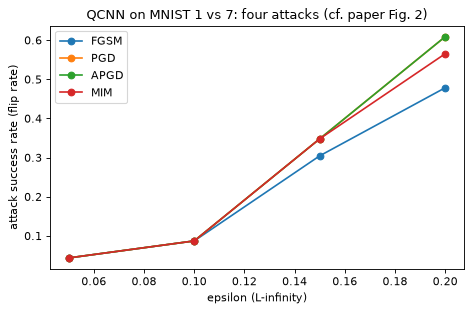

In [23]:
# ---- Experiment 3a (paper Fig. 2): which attack is strongest? QCNN on MNIST, eps = 0.05 ... 0.20 ----
t = TASKS["mnist"]; model = TRAINED[("mnist", "QCNN")]
xa_, ya_ = t["Xte"][:N_ATTACK], t["yte"][:N_ATTACK]
FIG2 = []
t0 = time.time()
for eps in (0.05, 0.10, 0.15, 0.20):
    for an, fn in ATTACKS.items():
        xadv = fn(model, xa_, ya_, eps, steps=APGD_STEPS if an == "APGD" else PGD_STEPS)
        FIG2.append(dict(attack=an, eps=eps, **attack_stats(model, xa_, ya_, xadv)))
FIG2 = pd.DataFrame(FIG2)
print(f"{time.time() - t0:.0f} s; every perturbation respects the budget: max |x_adv - x| = {FIG2['linf'].max():.3f} <= 0.20")
display(FIG2.pivot(index="attack", columns="eps", values="flip_rate").round(3).rename_axis("flip rate among correctly classified"))
display(FIG2.pivot(index="attack", columns="eps", values="adv_acc").round(3).rename_axis("adversarial accuracy"))
fig, ax = plt.subplots(figsize=(6, 4))
for an in ATTACKS:
    d = FIG2[FIG2.attack == an]; ax.plot(d.eps, d.flip_rate, marker="o", label=an)
ax.set_xlabel("epsilon (L-infinity)"); ax.set_ylabel("attack success rate (flip rate)"); ax.set_title("QCNN on MNIST 1 vs 7: four attacks (cf. paper Fig. 2)"); ax.legend()
plt.tight_layout(); plt.show()


### APGD against the three networks (paper Table 3 and Fig. 8)

For each network and each $\epsilon$ the table gives the accuracy on the attacked images (`adv_acc`), the ASR in the paper's convention
(1 - adversarial accuracy), the flip rate among correctly classified images, and the **average fidelity** $|\langle\psi_{adv}|\psi_{clean}\rangle|^2$
between the quantum states that the model loads for the clean and the attacked image. Fidelity 1 means the attack did not change the quantum
input state at all.


  cifar/QCNN done, cumulative 130 s


  cifar/QRNN done, cumulative 390 s


  cifar/QViT done, cumulative 776 s


  mnist/QCNN done, cumulative 806 s


  mnist/QRNN done, cumulative 868 s


  mnist/QViT done, cumulative 1009 s


,task,model,eps,clean_acc,adv_acc,ASR,flip_rate,fidelity,linf,seconds
0,cifar,QCNN,0.1,0.542,0.083,0.917,0.846,0.978,0.1,42.444
1,cifar,QCNN,0.2,0.542,0.000,1.000,1.000,0.925,0.2,31.794
2,cifar,QCNN,0.3,0.542,0.000,1.000,1.000,0.860,0.3,33.487
3,cifar,QCNN,0.5,0.542,0.000,1.000,1.000,0.727,0.5,22.457
4,cifar,QRNN,0.1,0.667,0.333,0.667,0.500,0.881,0.1,69.448
5,cifar,QRNN,0.2,0.667,0.083,0.917,0.875,0.649,0.2,68.455
6,cifar,QRNN,0.3,0.667,0.000,1.000,1.000,0.480,0.3,61.137
7,cifar,QRNN,0.5,0.667,0.000,1.000,1.000,0.315,0.5,61.183
8,cifar,QViT,0.1,0.708,0.042,0.958,0.941,0.999,0.1,88.264
9,cifar,QViT,0.2,0.708,0.000,1.000,1.000,0.997,0.2,90.935


APGD attack time 16.8 min


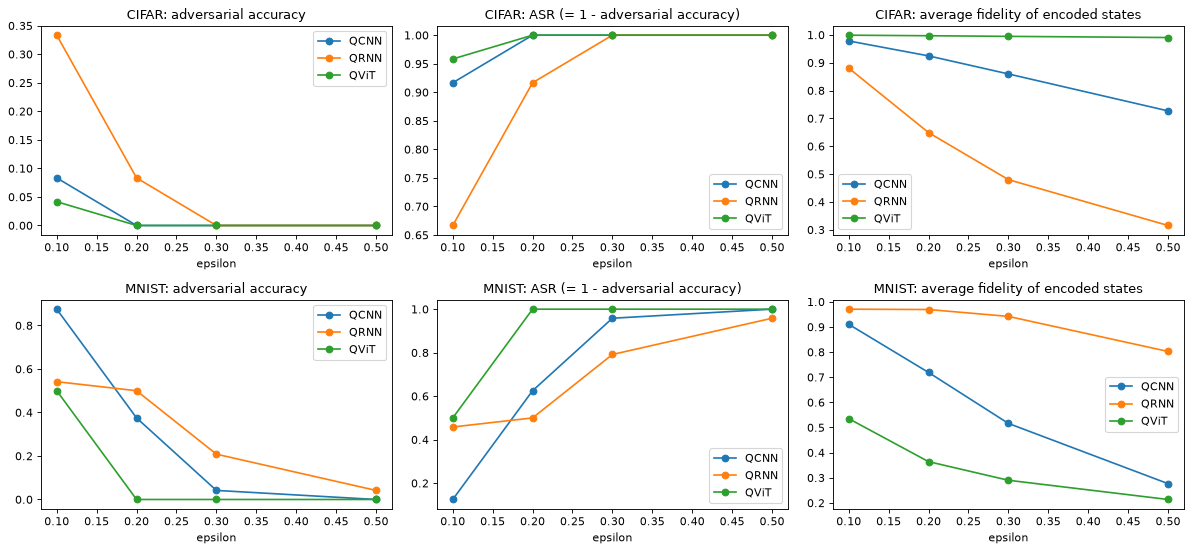

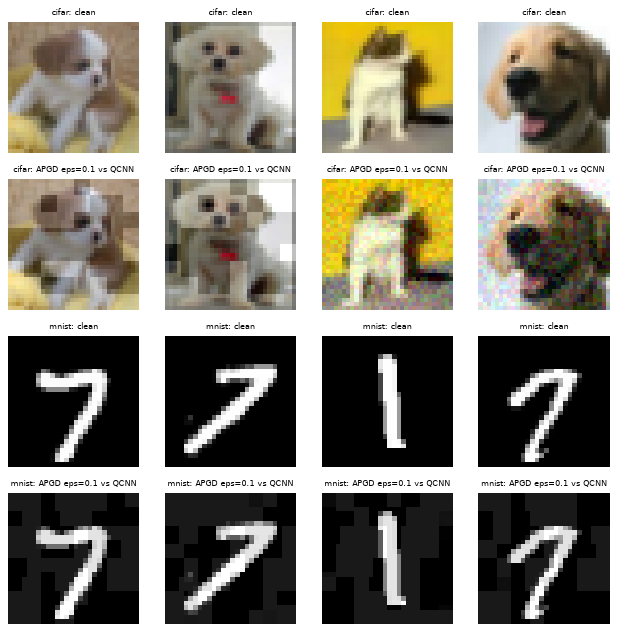

In [24]:
# ---- Experiment 3b (paper Table 3 and Fig. 8): APGD with eps in {0.1, 0.2, 0.3, 0.5} against the trained QCNN, QRNN, QViT ----
ATK = []; ADV_EX = {}
t0 = time.time()
for tk in ("cifar", "mnist"):
    t = TASKS[tk]; xa_, ya_ = t["Xte"][:N_ATTACK], t["yte"][:N_ATTACK]
    for mname in MODELS:
        model = TRAINED[(tk, mname)]
        for eps in EPS_LIST:
            t1 = time.time()
            xadv = apgd(model, xa_, ya_, eps, APGD_STEPS, seed=SEED)
            ATK.append(dict(task=tk, model=mname, eps=eps, **attack_stats(model, xa_, ya_, xadv), seconds=time.time() - t1))
            if eps == 0.1 and mname == "QCNN":
                ADV_EX[tk] = (xa_[:4], xadv[:4])
        print(f"  {tk}/{mname} done, cumulative {time.time() - t0:.0f} s", flush=True)
ATK = pd.DataFrame(ATK)
display(ATK.round(3))
print(f"APGD attack time {ATK['seconds'].sum() / 60:.1f} min")

fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for r_, tk in enumerate(("cifar", "mnist")):
    d = ATK[ATK.task == tk]
    for m in MODELS:
        dm = d[d.model == m]
        axs[r_, 0].plot(dm.eps, dm.adv_acc, marker="o", label=m); axs[r_, 1].plot(dm.eps, dm.ASR, marker="o", label=m)
        axs[r_, 2].plot(dm.eps, dm.fidelity, marker="o", label=m)
    for c_, ttl in enumerate(("adversarial accuracy", "ASR (= 1 - adversarial accuracy)", "average fidelity of encoded states")):
        axs[r_, c_].set_title(f"{tk.upper()}: {ttl}"); axs[r_, c_].set_xlabel("epsilon"); axs[r_, c_].legend()
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(4, 4, figsize=(8, 8))
for r_, tk in enumerate(("cifar", "mnist")):
    x0, xa0 = ADV_EX[tk]
    for k, (lab, imgs) in enumerate((("clean", x0), ("APGD eps=0.1 vs QCNN", xa0))):
        for q in range(4):
            a = imgs[q].permute(1, 2, 0).numpy(); ax = axs[2 * r_ + k, q]
            ax.imshow(a[..., 0] if a.shape[2] == 1 else a, cmap="gray" if a.shape[2] == 1 else None, vmin=0, vmax=1)
            ax.axis("off"); ax.set_title(f"{tk}: {lab}", fontsize=7)
plt.tight_layout(); plt.show()


In [25]:
# ---- context: the same APGD attack against the classical small CNN trained on the same images ----
CL = []
for tk in ("cifar", "mnist"):
    t = TASKS[tk]; xa_, ya_ = t["Xte"][:N_ATTACK], t["yte"][:N_ATTACK]
    class _Wrap(nn.Module):                         # give the CNN the same interface (fidelity of the raw pixels)
        def __init__(s, net): super().__init__(); s.net = net
        def forward(s, x): return s.net(x)
        def fidelity(s, x, xa): return F.cosine_similarity(x.flatten(1), xa.flatten(1)) ** 2
    w = _Wrap(CNN_MODELS[tk])
    for eps in EPS_LIST:
        CL.append(dict(task=tk, model="small CNN", eps=eps, **attack_stats(w, xa_, ya_, apgd(w, xa_, ya_, eps, APGD_STEPS, seed=SEED))))
CL = pd.DataFrame(CL)
display(CL[["task", "model", "eps", "clean_acc", "adv_acc", "ASR"]].round(3))


,task,model,eps,clean_acc,adv_acc,ASR
0,cifar,small CNN,0.1,0.667,0.000,1.000
1,cifar,small CNN,0.2,0.667,0.000,1.000
2,cifar,small CNN,0.3,0.667,0.000,1.000
3,cifar,small CNN,0.5,0.667,0.000,1.000
4,mnist,small CNN,0.1,0.958,0.667,0.333
5,mnist,small CNN,0.2,0.958,0.292,0.708
6,mnist,small CNN,0.3,0.958,0.208,0.792
7,mnist,small CNN,0.5,0.958,0.292,0.708


## 7. Generalisation error versus training-set size (paper Fig. 6)

Theory (Caro et al. 2022, quoted as Eq. 18) says that a model with $T$ trainable gates generalises with an error that scales like
$\sqrt{T\log T / N}$ with the training-set size $N$. The paper checks this for the QCNN on CIFAR-10 and finds an empirical log-log slope of
-0.521 against the theoretical -0.5. We train the QCNN for several $N$ on nested subsets of CIFAR-10 cat/dog images, measure
$|L_{test} - L_{train}|$ on a fixed test set and fit the slope. With a 54-parameter model the gap is small and noisy, so the fit is only as
good as the number of seeds allows.


  N = 60: done, cumulative 57 s


  N = 120: done, cumulative 192 s


  N = 240: done, cumulative 271 s


  N = 480: done, cumulative 503 s


,seed,train_loss,test_loss,gap,train_acc,test_acc
N,,,,,,
60,0.0,0.5985,0.7200,0.1216,0.6833,0.5100
120,0.0,0.6497,0.6924,0.0427,0.6500,0.5550
240,0.0,0.6572,0.6876,0.0304,0.6375,0.5775
480,0.0,0.6670,0.6839,0.0169,0.6062,0.5350


empirical log-log slope of the generalisation error: -0.904   (theory: -0.5; paper Fig. 6: -0.521); T = 54; fitted c = 0.0487 (paper: 0.0748)


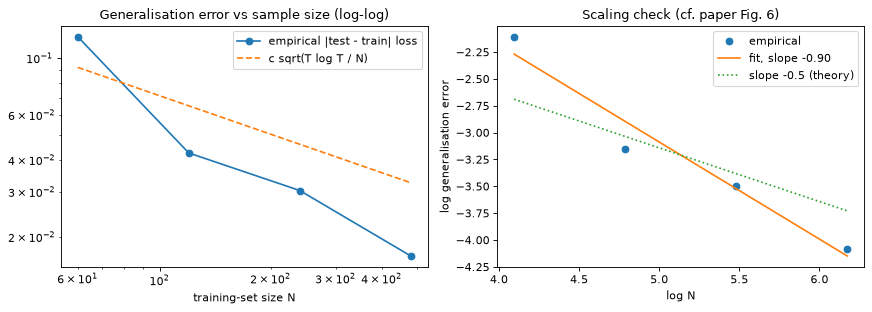

In [26]:
# ---- Experiment 4 (paper Fig. 6 and Eq. 18): does the generalisation error of the QCNN on CIFAR-10 cat vs dog shrink like sqrt(T log T / N)? ----
# generalisation error = |test loss - training loss| of the trained QCNN; T = number of trainable circuit parameters.
t = TASKS["cifar"]; tr, te = t["train_split"], t["test_split"]
N_GEN_TEST = 400 if FAST_MODE else 1000                                   # CHOICE: a larger fixed test set makes the loss estimate less noisy
gi, gy = balanced_pick(tr.labels, CIFAR_PAIR, max(GEN_SIZES), SEED + 7)
Xg, yg = torch.tensor(to_chw([tr.get(i) for i in gi])), torch.tensor(gy)
ti, ty = balanced_pick(te.labels, CIFAR_PAIR, N_GEN_TEST, SEED + 8)
Xgt, ygt = torch.tensor(to_chw([te.get(i) for i in ti])), torch.tensor(ty)
T_PARAMS = n_params(QCNN("cifar"), True)
GEN = []
t0 = time.time()
for n in GEN_SIZES:
    for s in range(GEN_SEEDS):
        torch.manual_seed(SEED + 1000 * s + n)
        m = QCNN("cifar")
        nv = max(n // 5, 20)                                              # hold out 1/5 of the n images for epoch selection
        train_model(m, Xg[:n], yg[:n], Xg[n:n + nv] if n + nv <= len(Xg) else Xg[:nv], yg[n:n + nv] if n + nv <= len(Xg) else yg[:nv],
                    GEN_EPOCHS, LR["QCNN"], SEED + s, bs=64, cosine=False, log_every=0)
        a, b = evaluate(m, Xg[:n], yg[:n]), evaluate(m, Xgt, ygt)
        GEN.append(dict(N=n, seed=s, train_loss=a["loss"], test_loss=b["loss"], gap=abs(b["loss"] - a["loss"]), train_acc=a["acc"], test_acc=b["acc"]))
    print(f"  N = {n}: done, cumulative {time.time() - t0:.0f} s", flush=True)
GEN = pd.DataFrame(GEN); G = GEN.groupby("N").mean(numeric_only=True)
display(G.round(4))
slope, icpt = np.polyfit(np.log(G.index.values), np.log(G["gap"].values.clip(1e-5)), 1)
c_fit = float(np.sum(G["gap"].values * np.sqrt(T_PARAMS * np.log(T_PARAMS) / G.index.values)) / np.sum(T_PARAMS * np.log(T_PARAMS) / G.index.values))
print(f"empirical log-log slope of the generalisation error: {slope:.3f}   (theory: -0.5; paper Fig. 6: -0.521); T = {T_PARAMS}; fitted c = {c_fit:.4f} (paper: 0.0748)")
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].loglog(G.index, G["gap"], "o-", label="empirical |test - train| loss")
axs[0].loglog(G.index, c_fit * np.sqrt(T_PARAMS * np.log(T_PARAMS) / G.index.values), "--", label="c sqrt(T log T / N)"); axs[0].set_xlabel("training-set size N"); axs[0].legend()
axs[0].set_title("Generalisation error vs sample size (log-log)")
axs[1].plot(np.log(G.index), np.log(G["gap"].clip(1e-5)), "o", label="empirical"); axs[1].plot(np.log(G.index), icpt + slope * np.log(G.index), label=f"fit, slope {slope:.2f}")
axs[1].plot(np.log(G.index), icpt + (-0.5) * np.log(G.index) + (np.mean(np.log(G["gap"].clip(1e-5))) - icpt - (-0.5) * np.mean(np.log(G.index))), ":", label="slope -0.5 (theory)")
axs[1].set_xlabel("log N"); axs[1].set_ylabel("log generalisation error"); axs[1].legend(); axs[1].set_title("Scaling check (cf. paper Fig. 6)")
plt.tight_layout(); plt.show()


## 8. Quantum noise (paper Fig. 9 and Sec. 5.4.3)

The trained QRNN and QCNN are re-evaluated on a density-matrix simulator with a noise channel after every gate block: depolarizing, bit flip,
phase flip, phase damping and amplitude damping with probability $p$; a symmetric readout error that flips each measured bit with probability $p$;
and a finite number of shots. Only inference is noisy here; the paper also mentions noise during training, which would multiply the cost.

Two remarks help reading the curves. A readout error with the same probability on both outcomes multiplies every $\langle Z_j\rangle$ by
$(1-2p)$; the QRNN prediction is the sign of gain times their sum plus a bias, so with a small bias its accuracy hardly changes, which agrees with the flat curves of the paper's Fig. 9a/d.
Amplitude damping pulls every qubit towards $|0\rangle$, i.e. $\langle Z\rangle \to +1$, so the network ends up always answering the same class
and the accuracy of a balanced test set sinks to 0.5 or below.


In [27]:
# ---- quantum-noise machinery (paper Sec. 5.4.3 / Fig. 9): density-matrix simulation of the trained circuits with a channel after every gate block ----
CHANNELS = {"Depolarizing": qml.DepolarizingChannel, "Bit flip": qml.BitFlip, "Phase flip": qml.PhaseFlip,
            "Phase damping": qml.PhaseDamping, "Amplitude damping": qml.AmplitudeDamping}

def noisy_qrnn_node(ch):
    def body(seq, rot, zz, ry, p):                        # CHOICE: channel on every active qubit after each time step's gate block
        return qrnn_windowed_body(seq, rot, zz, ry, noise=lambda q: ch(p, wires=q))
    return qml.QNode(body, dev_qrnn, interface="torch", diff_method="backprop")

dev_qcnn_mixed = qml.device("default.mixed", wires=6)
def noisy_qcnn_node(ch):
    def body(x, w1, p1, w2, p2, wf, p):                   # CHOICE: channel on the active qubits after each convolution layer
        return qcnn_body(x, w1, p1, w2, p2, wf, noise=lambda q: ch(p, wires=q))
    return qml.QNode(body, dev_qcnn_mixed, interface="torch", diff_method="backprop")

prob_node = qml.QNode(lambda seq, rot, zz, ry: qrnn_windowed_body(seq, rot, zz, ry, probs=True), dev_qrnn, interface="torch", diff_method="backprop")

def acc_from_logit(z, y):
    return float(((z > 0).long() == y).double().mean())

# sanity: with p = 0 every noisy circuit must reproduce the noiseless model
mq = TRAINED[("mnist", "QRNN")]; xs = TASKS["mnist"]["Xte"][:6]; ys = TASKS["mnist"]["yte"][:6]
with torch.no_grad():
    d1 = (mq.gain * noisy_qrnn_node(qml.DepolarizingChannel)(mq.seq(xs), mq.rot, mq.zz, mq.ry, 0.0) + mq.bias - mq(xs)).abs().max()
    mc = TRAINED[("mnist", "QCNN")]
    d2 = (noisy_qcnn_node(qml.DepolarizingChannel)(mc.encode(xs), mc.w1, mc.p1, mc.w2, mc.p2, mc.wf, 0.0) - qcnn_node(mc.encode(xs), mc.w1, mc.p1, mc.w2, mc.p2, mc.wf)).abs().max()
print(f"p = 0 consistency: QRNN {float(d1):.1e}, QCNN {float(d2):.1e}")
assert float(d1) < 1e-8 and float(d2) < 1e-8


p = 0 consistency: QRNN 5.6e-13, QCNN 1.4e-13


  mnist done, cumulative 108 s


  cifar done, cumulative 257 s


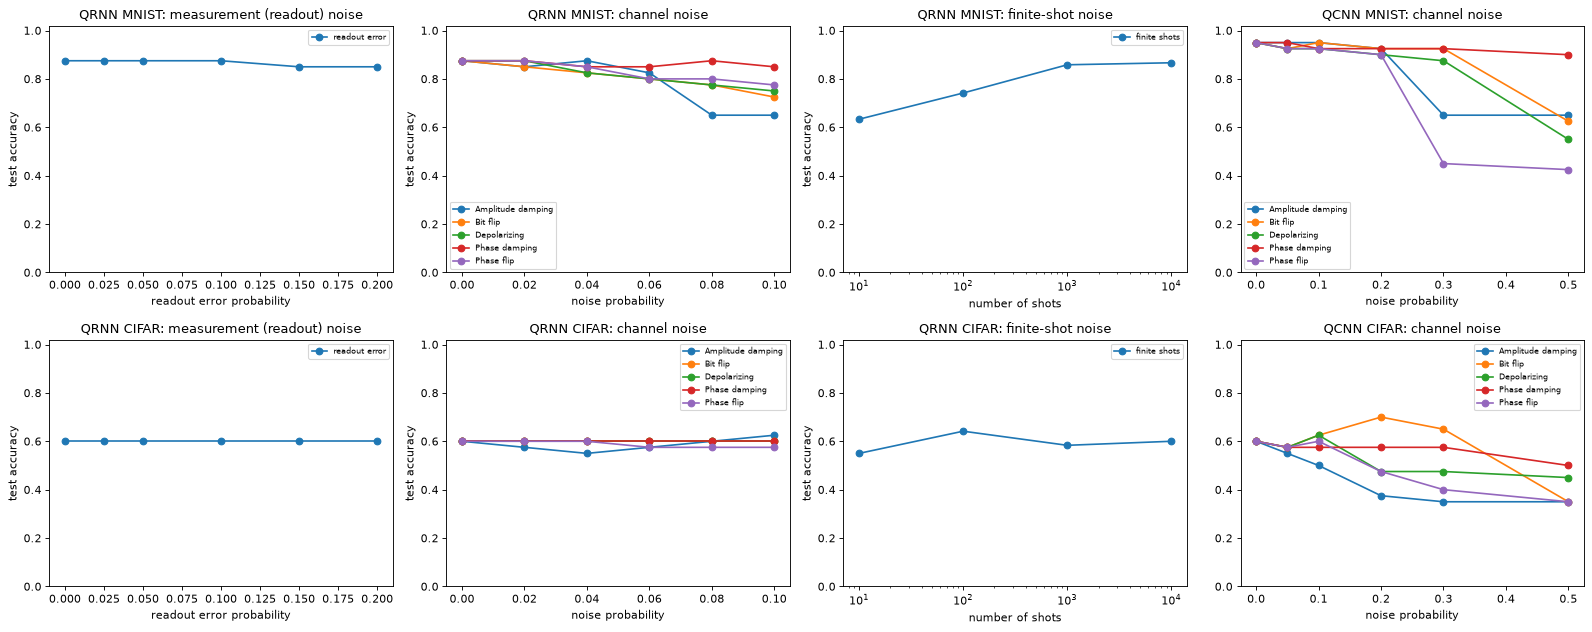

QRNN: test accuracy under channel noise (columns = noise probability p)


p                        0.00  0.02  0.04  0.06  0.08  0.10
task  name                                                 
cifar Amplitude damping  0.60  0.57  0.55  0.57  0.60  0.62
      Bit flip           0.60  0.60  0.60  0.60  0.60  0.60
      Depolarizing       0.60  0.60  0.60  0.60  0.60  0.60
      Phase damping      0.60  0.60  0.60  0.60  0.60  0.60
      Phase flip         0.60  0.60  0.60  0.57  0.57  0.57
mnist Amplitude damping  0.88  0.85  0.88  0.82  0.65  0.65
      Bit flip           0.88  0.85  0.82  0.80  0.78  0.72
      Depolarizing       0.88  0.88  0.82  0.80  0.78  0.75
      Phase damping      0.88  0.88  0.85  0.85  0.88  0.85
      Phase flip         0.88  0.88  0.85  0.80  0.80  0.78

QCNN: test accuracy under channel noise (columns = noise probability p)


p                        0.00  0.05  0.10  0.20  0.30  0.50
task  name                                                 
cifar Amplitude damping  0.60  0.55  0.50  0.38  0.35  0.35
      Bit flip           0.60  0.57  0.62  0.70  0.65  0.35
      Depolarizing       0.60  0.57  0.62  0.48  0.48  0.45
      Phase damping      0.60  0.57  0.57  0.57  0.57  0.50
      Phase flip         0.60  0.57  0.60  0.48  0.40  0.35
mnist Amplitude damping  0.95  0.95  0.95  0.92  0.65  0.65
      Bit flip           0.95  0.92  0.95  0.92  0.92  0.62
      Depolarizing       0.95  0.92  0.92  0.90  0.88  0.55
      Phase damping      0.95  0.95  0.92  0.92  0.92  0.90
      Phase flip         0.95  0.92  0.92  0.90  0.45  0.42

QRNN: readout error and finite shots


p                    0.000      0.025      0.050      0.100      0.150      \
task  name                                                                   
cifar finite shots         NaN        NaN        NaN        NaN        NaN   
      readout error       0.60       0.60       0.60       0.60       0.60   
mnist finite shots         NaN        NaN        NaN        NaN        NaN   
      readout error       0.88       0.88       0.88       0.88       0.85   

p                    0.200      10.000     100.000    1000.000   10000.000  
task  name                                                                  
cifar finite shots         NaN       0.55       0.64       0.58       0.60  
      readout error       0.60        NaN        NaN        NaN        NaN  
mnist finite shots         NaN       0.63       0.74       0.86       0.87  
      readout error       0.85        NaN        NaN        NaN        NaN

In [28]:
# ---- Experiment 5: accuracy of the TRAINED models under channel noise, readout error and finite shots (noise applied at inference) ----
NZ = []
t0 = time.time()
for tk in ("mnist", "cifar"):
    t = TASKS[tk]; x, y = t["Xte"][:N_NOISE], t["yte"][:N_NOISE]
    m = TRAINED[(tk, "QRNN")]; seq = m.seq(x)
    with torch.no_grad():
        for cname, ch in CHANNELS.items():
            node = noisy_qrnn_node(ch)
            for p in NOISE_P["QRNN"]:
                z = m.gain * node(seq, m.rot, m.zz, m.ry, p) + m.bias
                NZ.append(dict(task=tk, model="QRNN", kind="channel", name=cname, p=p, acc=acc_from_logit(z, y)))
        z0raw = qrnn_node(seq, m.rot, m.zz, m.ry)
        for p in READOUT_P:                               # symmetric readout error: <Z_j> -> (1 - 2p) <Z_j>, so <O> -> (1 - 2p) <O>
            NZ.append(dict(task=tk, model="QRNN", kind="readout", name="readout error", p=p, acc=acc_from_logit(m.gain * (1 - 2 * p) * z0raw + m.bias, y)))
        probs = prob_node(seq, m.rot, m.zz, m.ry).numpy()                # exact joint distribution of the 3 measured qubits
        parity = np.array([sum(1 - 2 * int(b) for b in format(k, "03b")) for k in range(8)])      # value of O for each bitstring
        r = np.random.default_rng(SEED)
        for S in SHOT_LIST:
            accs = []
            for _rep in range(SHOT_REPEATS):
                est = np.array([(r.multinomial(S, pr / pr.sum()) * parity).sum() / S for pr in probs])   # estimated <O> from S shots
                accs.append(acc_from_logit(m.gain * torch.tensor(est) + m.bias, y))
            NZ.append(dict(task=tk, model="QRNN", kind="shots", name="finite shots", p=S, acc=float(np.mean(accs))))
    mc = TRAINED[(tk, "QCNN")]; amp = mc.encode(x)
    with torch.no_grad():
        for cname, ch in CHANNELS.items():
            node = noisy_qcnn_node(ch)
            for p in NOISE_P["QCNN"]:
                zz_ = node(amp, mc.w1, mc.p1, mc.w2, mc.p2, mc.wf, p).clamp(-1 + 1e-7, 1 - 1e-7)
                NZ.append(dict(task=tk, model="QCNN", kind="channel", name=cname, p=p, acc=acc_from_logit(-2 * torch.atanh(zz_), y)))
    print(f"  {tk} done, cumulative {time.time() - t0:.0f} s", flush=True)
NZ = pd.DataFrame(NZ)

fig, axs = plt.subplots(2, 4, figsize=(20, 8))
for r_, tk in enumerate(("mnist", "cifar")):
    d = NZ[(NZ.task == tk) & (NZ.model == "QRNN")]
    for c_, (kind, ttl, xl) in enumerate((("readout", "measurement (readout) noise", "readout error probability"),
                                         ("channel", "channel noise", "noise probability"), ("shots", "finite-shot noise", "number of shots"))):
        for nm, g in d[d.kind == kind].groupby("name"):
            axs[r_, c_].plot(g.p, g.acc, marker="o", label=nm)
        axs[r_, c_].set_title(f"QRNN {tk.upper()}: {ttl}"); axs[r_, c_].set_xlabel(xl); axs[r_, c_].set_ylabel("test accuracy"); axs[r_, c_].set_ylim(0, 1.02)
        axs[r_, c_].legend(fontsize=7)
        if kind == "shots": axs[r_, c_].set_xscale("log")
    dq = NZ[(NZ.task == tk) & (NZ.model == "QCNN")]
    for nm, g in dq.groupby("name"):
        axs[r_, 3].plot(g.p, g.acc, marker="o", label=nm)
    axs[r_, 3].set_title(f"QCNN {tk.upper()}: channel noise"); axs[r_, 3].set_xlabel("noise probability"); axs[r_, 3].set_ylim(0, 1.02); axs[r_, 3].legend(fontsize=7)
plt.tight_layout(); plt.show()
for mname_ in ("QRNN", "QCNN"):
    print(f"{mname_}: test accuracy under channel noise (columns = noise probability p)")
    display(NZ[(NZ.kind == "channel") & (NZ.model == mname_)].pivot_table(index=["task", "name"], columns="p", values="acc").round(2))
print("QRNN: readout error and finite shots")
display(NZ[(NZ.model == "QRNN") & NZ.kind.isin(["readout", "shots"])].pivot_table(index=["task", "name"], columns="p", values="acc").round(2))


## 9. Side by side with the paper

One row per checkable claim. "reproduced" means within 2 percentage points (accuracy, ASR), 0.05 (loss), 0.02 (fidelity, generalisation
gap), a factor 2 (Lipschitz bound), 0.1 (log-log slope), or that the qualitative ordering holds. Quantities that the paper gives for 10,000+ training
images and 100 epochs are compared with our much smaller runs, so a mismatch in the absolute numbers mostly measures the budget, not the paper.


In [29]:
# ---- side-by-side comparison with the paper: one verdict per checkable claim ----
def _row(claim, paper, nb, tol, unit="", note="", better=False):
    """better=True: a higher value is better (accuracy) -> 'exceeded' / 'not reached'; otherwise 'differs' with the direction."""
    d = nb - paper
    if abs(d) <= tol:
        v, cls = "reproduced", "reproduced"
    elif better:
        v, cls = (f"exceeded (+{d:.3g}{unit})", "exceeded") if d > 0 else (f"not reached ({d:.3g}{unit})", "not reached")
    else:
        v, cls = (f"not reproduced: above paper by +{d:.3g}{unit}" if d > 0 else f"not reproduced: below paper by {d:.3g}{unit}"), "not reproduced"
    return dict(claim=claim, paper=paper, notebook=round(float(nb), 4), tolerance=tol, verdict=v, verdict_class=cls, note=note)

def _flag(claim, paper_text, nb_text, ok, note=""):
    return dict(claim=claim, paper=paper_text, notebook=nb_text, tolerance="qualitative", verdict="reproduced" if ok else "not reproduced",
                verdict_class="reproduced" if ok else "not reproduced", note=note)

S_ = SUMMARY.set_index(["model", "task"]); L_ = LIP.set_index(["model", "task"])
A_ = ATK.set_index(["model", "task", "eps"])
rows = []
# --- Table 1 (accuracy within 2 points, loss within 0.05, generalisation bound within 0.02) ---
P1 = {("QCNN", "cifar"): (55.5, 0.48, 0.003), ("QCNN", "mnist"): (97.3, 0.23, 0.002), ("QRNN", "cifar"): (57.1, 0.67, 0.013),
      ("QRNN", "mnist"): (96.7, 0.23, 0.003), ("QViT", "cifar"): (69.2, 0.63, 0.22), ("QViT", "mnist"): (99.5, 0.02, 0.02)}
for (m, tk), (acc, loss, gb) in P1.items():
    rows.append(_row(f"Table 1 accuracy {m} {tk.upper()} (%)", acc, 100 * S_.loc[(m, tk), "acc_mean"], 2.0, " pts", better=True))
    rows.append(_row(f"Table 1 loss {m} {tk.upper()}", loss, S_.loc[(m, tk), "loss"], 0.05))
    rows.append(_row(f"Table 1 generalisation bound {m} {tk.upper()}", gb, S_.loc[(m, tk), "gen_gap"], 0.02, note="notebook value = |test loss - train loss| (definition guessed)"))
# --- Table 2 (Lipschitz bound: same order of magnitude = within a factor 2) ---
P2 = {("QCNN", "cifar"): 0.67, ("QCNN", "mnist"): 1.09, ("QRNN", "cifar"): 0.033, ("QRNN", "mnist"): 0.12, ("QViT", "cifar"): 61.38, ("QViT", "mnist"): 68.1}
for (m, tk), v in P2.items():
    nb = L_.loc[(m, tk), "L2_logit_max"]; ratio = nb / v
    ok = 0.5 <= ratio <= 2
    rows.append(dict(claim=f"Table 2 Lipschitz bound {m} {tk.upper()}", paper=v, notebook=round(float(nb), 4), tolerance="factor 2",
                     verdict="reproduced" if ok else f"not reproduced: {'above' if ratio > 2 else 'below'} paper by a factor {ratio:.2g}",
                     verdict_class="reproduced" if ok else "not reproduced", note="max gradient L2-norm of the logit over training images"))
# --- Table 3 (CIFAR-10 cat vs dog, APGD): ASR within 2 points, fidelity within 0.02 ---
P3 = {"QCNN": ([68.4, 70, 71.4, 73.4], [0.73, 0.71, 0.70, 0.67]), "QRNN": ([52.4, 52.9, 53.5, 54.5], [0.671, 0.670, 0.669, 0.668]),
      "QViT": ([100] * 4, [0.86, 0.72, 0.61, 0.45])}
for m, (asr, fid) in P3.items():
    for e, a_, f_ in zip(EPS_LIST, asr, fid):
        rows.append(_row(f"Table 3 ASR {m} eps={e} (%)", a_, 100 * A_.loc[(m, "cifar", e), "ASR"], 2.0, " pts"))
        rows.append(_row(f"Table 3 fidelity {m} eps={e}", f_, A_.loc[(m, "cifar", e), "fidelity"], 0.02))
# --- text values: adversarial accuracy of QCNN / QRNN ---
rows.append(_row("Text: QCNN CIFAR adversarial accuracy eps=0.1 (%)", 31.6, 100 * A_.loc[("QCNN", "cifar", 0.1), "adv_acc"], 2.0, " pts", better=True))
rows.append(_row("Text: QRNN CIFAR adversarial accuracy eps=0.1 (%)", 47.6, 100 * A_.loc[("QRNN", "cifar", 0.1), "adv_acc"], 2.0, " pts", better=True))
rows.append(_row("Text: QRNN CIFAR adversarial accuracy eps=0.5 (%)", 45.5, 100 * A_.loc[("QRNN", "cifar", 0.5), "adv_acc"], 2.0, " pts", better=True))
rows.append(_row("Text: QViT CIFAR adversarial accuracy eps=0.1 (%)", 0.0, 100 * A_.loc[("QViT", "cifar", 0.1), "adv_acc"], 2.0, " pts", better=True))

# --- qualitative claims (orderings and trends) ---
acc = lambda m, tk: S_.loc[(m, tk), "acc_mean"]
rows.append(_flag("MNIST accuracy > CIFAR-10 accuracy for all three models", "97.3/96.7/99.5 vs 55.5/57.1/69.2",
                  "; ".join(f"{m} {100 * acc(m, 'mnist'):.0f} vs {100 * acc(m, 'cifar'):.0f}" for m in MODELS),
                  all(acc(m, "mnist") - acc(m, "cifar") > 0.15 for m in MODELS)))
rows.append(_flag("QViT has the highest CIFAR-10 accuracy", "QViT 69.2 > QRNN 57.1 > QCNN 55.5", f"{ {m: round(100 * acc(m, 'cifar'), 1) for m in MODELS} }",
                  acc("QViT", "cifar") >= max(acc("QCNN", "cifar"), acc("QRNN", "cifar"))))
rows.append(_flag("QRNN beats QCNN on CIFAR-10", "57.1 vs 55.5", f"{100 * acc('QRNN', 'cifar'):.1f} vs {100 * acc('QCNN', 'cifar'):.1f}", acc("QRNN", "cifar") > acc("QCNN", "cifar")))
rows.append(_flag("QViT has by far the most trainable parameters", "yes (text)", f"{S_.loc[('QViT', 'cifar'), 'params']} vs {S_.loc[('QCNN', 'cifar'), 'params']} / {S_.loc[('QRNN', 'cifar'), 'params']}",
                  S_.loc[("QViT", "cifar"), "params"] > 10 * S_.loc[("QCNN", "cifar"), "params"]))
lip = lambda m, tk: L_.loc[(m, tk), "L2_logit_max"]
rows.append(_flag("Lipschitz ordering QViT >> QCNN > QRNN (both datasets)", "61.4 > 0.67 > 0.033; 68.1 > 1.09 > 0.12",
                  "; ".join(f"{tk}: " + " > ".join(f"{m} {lip(m, tk):.3g}" for m in sorted(MODELS, key=lambda m: -lip(m, tk))) for tk in ("cifar", "mnist")),
                  all(lip("QViT", tk) > lip("QCNN", tk) > lip("QRNN", tk) for tk in ("cifar", "mnist"))))
adv = lambda m, e: A_.loc[(m, "cifar", e), "adv_acc"]
rows.append(_flag("QViT is the most vulnerable to APGD (lowest adversarial accuracy at every eps, CIFAR-10)", "QViT 0 %", f"{ {m: round(100 * adv(m, 0.1), 1) for m in MODELS} } at eps=0.1",
                  all(adv("QViT", e) <= min(adv("QCNN", e), adv("QRNN", e)) + 1e-9 for e in EPS_LIST)))
rows.append(_flag("QRNN keeps the highest adversarial accuracy at eps=0.1 (CIFAR-10)", "QRNN 47.6 vs QCNN 31.6", f"QRNN {100 * adv('QRNN', 0.1):.1f} vs QCNN {100 * adv('QCNN', 0.1):.1f}",
                  adv("QRNN", 0.1) >= adv("QCNN", 0.1)))
fd = lambda m, e: A_.loc[(m, "cifar", e), "fidelity"]
rows.append(_flag("Fidelity of QViT's encoded states falls sharply with eps while QRNN's stays almost flat", "QViT 0.86 -> 0.45; QRNN 0.671 -> 0.668",
                  f"QViT {fd('QViT', 0.1):.2f} -> {fd('QViT', 0.5):.2f}; QRNN {fd('QRNN', 0.1):.3f} -> {fd('QRNN', 0.5):.3f}",
                  (fd("QViT", 0.1) - fd("QViT", 0.5)) > 0.2 and abs(fd("QRNN", 0.1) - fd("QRNN", 0.5)) < 0.05))
f2 = FIG2.groupby("attack")["flip_rate"].mean()
rows.append(_flag("APGD is (jointly with PGD) the strongest of the four attacks (Fig. 2, QCNN, MNIST)", "PGD, APGD highest", f"mean flip rate { {k: round(v, 3) for k, v in f2.items()} }",
                  f2["APGD"] >= f2.max() - 0.02))
rows.append(_row("Fig. 6 log-log slope of the generalisation error (QCNN, CIFAR-10)", -0.521, slope, 0.1, note="theory -0.5; tolerance 0.1"))
bq = BASE[(BASE.task == "cifar")]["test_acc"].max()
rows.append(_flag("QCNN is less effective than other (classical) architectures on high-feature CIFAR-10 data", "stated, no number", f"QCNN {100 * acc('QCNN', 'cifar'):.1f} vs best classical {100 * bq:.1f}", acc("QCNN", "cifar") + 0.02 < bq))
# --- quantum-noise claims ---
nz = NZ.set_index(["task", "model", "kind", "name", "p"])["acc"]
clean = {(tk, m): float(nz.loc[(tk, m, "channel", "Depolarizing", 0.0)]) for tk in ("mnist", "cifar") for m in ("QRNN", "QCNN")}
rows.append(_flag("QRNN accuracy is unaffected by measurement (readout) noise", "Fig. 9a/d flat", f"max accuracy change {max(abs(nz.loc[('mnist', 'QRNN', 'readout', 'readout error', p)] - clean[('mnist', 'QRNN')]) for p in READOUT_P):.3f} (MNIST)",
                  all(abs(nz.loc[(tk, "QRNN", "readout", "readout error", p)] - clean[(tk, "QRNN")]) <= 0.03 for tk in ("mnist", "cifar") for p in READOUT_P),
                  note="symmetric readout error rescales <O> by (1-2p) and cannot change its sign; only the learned bias can move the decision, so this is nearly true by construction"))
big = max(SHOT_LIST)
rows.append(_flag(f"QRNN accuracy is unaffected by the number of shots (from 1000 up)", "Fig. 9c/f flat", f"MNIST {nz.loc[('mnist', 'QRNN', 'shots', 'finite shots', 1000)]:.2f} vs clean {clean[('mnist', 'QRNN')]:.2f}",
                  all(abs(nz.loc[(tk, "QRNN", "shots", "finite shots", S)] - clean[(tk, "QRNN")]) <= 0.06 for tk in ("mnist", "cifar") for S in SHOT_LIST if S >= 1000)))
drops = {c: max(clean[(tk, "QRNN")] - nz.loc[(tk, "QRNN", "channel", c, 0.1)] for tk in ("mnist", "cifar")) for c in ("Depolarizing", "Bit flip", "Phase flip", "Amplitude damping")}
rows.append(_flag("QRNN accuracy degrades under all four channel types (p up to 0.1)", "'noticeable degradation' for all four", f"largest drop per channel { {k: round(v, 2) for k, v in drops.items()} }",
                  all(v >= 0.05 for v in drops.values())))
rows.append(_row("QRNN MNIST accuracy under amplitude damping at p = 0.1", 0.4, nz.loc[("mnist", "QRNN", "channel", "Amplitude damping", 0.1)], 0.1, note="paper: 'drops to approximately 0.4 and plateaus' (read from text)"))
dep = {tk: clean[(tk, "QCNN")] - nz.loc[(tk, "QCNN", "channel", "Depolarizing", 0.3)] for tk in ("mnist", "cifar")}
pha = {tk: clean[(tk, "QCNN")] - min(nz.loc[(tk, "QCNN", "channel", c, 0.3)] for c in ("Phase damping", "Phase flip")) for tk in ("mnist", "cifar")}
rows.append(_flag("QCNN is highly sensitive to depolarizing noise (sharp decline beyond p = 0.2)", "stated", f"accuracy drop at p=0.3: { {k: round(v, 2) for k, v in dep.items()} }", dep["mnist"] > 0.1))
rows.append(_flag("QCNN is far more robust to phase damping / phase flip than to depolarizing noise", "stated", f"drop at p=0.3: phase {pha['mnist']:.2f} vs depolarizing {dep['mnist']:.2f} (MNIST)", pha["mnist"] < dep["mnist"]))
rows.append(dict(claim="QViT is the architecture least affected by quantum noise", paper="abstract / intro", notebook="not run", tolerance="-", verdict="cannot be checked", verdict_class="cannot be checked",
                 note="the paper's own Sec. 5.4.3 says no clear effect was observed for QViT; no noisy QViT simulation here (cost)"))
rows.append(dict(claim="Lipschitz bound of QViT grows with training epochs; loss landscapes show no barren plateau (Fig. 4, 7)", paper="stated", notebook="not run", tolerance="-", verdict="cannot be checked", verdict_class="cannot be checked",
                 note="needs 100 epochs on 10,000 images per model; outside the CPU budget"))
CMP = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 200)
display(CMP[["claim", "paper", "notebook", "tolerance", "verdict"]])
print(CMP.verdict_class.value_counts().to_dict(), "of", len(CMP), "claims")


,claim,paper,notebook,tolerance,verdict
0,Table 1 accuracy QCNN CIFAR (%),55.5,63.3,2.0,exceeded (+7.8 pts)
1,Table 1 loss QCNN CIFAR,0.48,0.656,0.05,not reproduced: above paper by +0.176
2,Table 1 generalisation bound QCNN CIFAR,0.003,0.014,0.02,reproduced
3,Table 1 accuracy QCNN MNIST (%),97.3,96.7,2.0,reproduced
4,Table 1 loss QCNN MNIST,0.23,0.307,0.05,not reproduced: above paper by +0.077
5,Table 1 generalisation bound QCNN MNIST,0.002,0.01,0.02,reproduced
6,Table 1 accuracy QRNN CIFAR (%),57.1,59.2,2.0,exceeded (+2.1 pts)
7,Table 1 loss QRNN CIFAR,0.67,0.681,0.05,reproduced
8,Table 1 generalisation bound QRNN CIFAR,0.013,0.005,0.02,reproduced
9,Table 1 accuracy QRNN MNIST (%),96.7,90.8,2.0,not reached (-5.9 pts)


{'not reproduced': 40, 'reproduced': 21, 'not reached': 5, 'exceeded': 3, 'cannot be checked': 2} of 71 claims


In [30]:
# compact headline numbers for the manifest
head = {
 "acc_cifar": {m: round(100 * S_.loc[(m, "cifar"), "acc_mean"], 1) for m in MODELS},
 "acc_mnist": {m: round(100 * S_.loc[(m, "mnist"), "acc_mean"], 1) for m in MODELS},
 "lipschitz_cifar": {m: round(float(L_.loc[(m, "cifar"), "L2_logit_max"]), 3) for m in MODELS},
 "ASR_cifar_eps0.1": {m: round(100 * A_.loc[(m, "cifar", 0.1), "ASR"], 1) for m in MODELS},
 "fidelity_cifar_eps0.1": {m: round(float(A_.loc[(m, "cifar", 0.1), "fidelity"]), 3) for m in MODELS},
 "gen_slope": round(float(slope), 3),
}
for k, v in head.items():
    print(f"{k:24s}", v)


acc_cifar                {'QCNN': np.float64(63.3), 'QRNN': np.float64(59.2), 'QViT': np.float64(53.3)}
acc_mnist                {'QCNN': np.float64(96.7), 'QRNN': np.float64(90.8), 'QViT': np.float64(99.2)}
lipschitz_cifar          {'QCNN': 0.361, 'QRNN': 0.067, 'QViT': 0.324}
ASR_cifar_eps0.1         {'QCNN': np.float64(91.7), 'QRNN': np.float64(66.7), 'QViT': np.float64(95.8)}
fidelity_cifar_eps0.1    {'QCNN': 0.978, 'QRNN': 0.881, 'QViT': 0.999}
gen_slope                -0.904


## 10. Reading the paper critically

**What this run shows (FAST_MODE, 240 training and 120 test images per task, one seed).** Of 71 checkable claims, 21 are reproduced, 3 exceeded, 5 not reached, 40 not reproduced and 2 cannot be checked (see the table above). The clean-accuracy picture of Table 1 is reproduced where the budget allows: QCNN 96.7 % and QViT 99.2 % on MNIST 1 vs 7 (paper 97.3 and 99.5), QRNN 90.8 % (paper 96.7, not reached). On CIFAR-10 cat vs dog every model is at chance level within the statistical error of a 120-image test set (plus or minus about 4.5 points): QCNN 63.3 %, QRNN 59.2 %, QViT 53.3 % (paper 55.5, 57.1, 69.2). The paper's CIFAR-10 ordering "QViT best" therefore cannot be confirmed; in FAST mode the QViT uses d_model = 32 instead of 96 and has only 240 images to fit about 17,000 parameters. A random forest on the 64 QCNN amplitudes reaches 71.7 %, so the "QCNN is weaker than other architectures on high-feature data" claim is supported, but with such small samples nothing beyond that can be said.

**Robustness.** The qualitative message of the paper partly survives. APGD is jointly the strongest attack (PGD and APGD equal, FGSM weakest; Fig. 2 pattern reproduced, and the QCNN flip rate at eps = 0.05 and 0.10 on MNIST, 4.3 % and 8.7 %, is close to the paper's 4.5 % and 11.4 %). The QRNN keeps the highest adversarial accuracy at eps = 0.1 on CIFAR-10 (33 % against 8 % for the QCNN and 4 % for the QViT), and on MNIST the QViT collapses fastest (0 % at eps = 0.2 against 50 % for the QRNN) and its encoded states lose fidelity fastest (0.54 at eps = 0.1, 0.21 at eps = 0.5). The absolute numbers differ strongly from Table 3 (our ASR is 14 to 46 points higher for QCNN and QRNN): our attack has exact gradients, the models are small and weakly trained, eps up to 0.5 in a [0, 1] pixel scale is a very large perturbation, and 24 attacked images give a standard error of about 10 points. The Lipschitz ordering QViT >> QCNN > QRNN holds on MNIST (16.0 > 1.9 > 1.15) but not on CIFAR-10 (0.32, 0.36, 0.067), where the QViT has barely left its initial state.

**Things to question in the paper.**
* *No classical reference for robustness.* "Traditional architectures resist adversarial noise" is not compared with a classical network. In this notebook a small CNN is broken by the same attack (0 % accuracy at eps = 0.1 on CIFAR-10, 67 % to 29 % on MNIST), so the robustness of the QRNN is mostly the robustness of a model that sees six or ten region means; averaging pixels shrinks the gradient with respect to any single pixel (hence the tiny Lipschitz constant), it does not make the decision boundary safe.
* *Ill-defined quantities.* The ASR is never defined (we infer 100 minus adversarial accuracy from the text); Fig. 2 shows ASR values from 0.04 to 0.48 for eps 0.05 to 0.2, which cannot come from CIFAR-10 at 55 % accuracy, so it must be a different dataset or definition; the "generalization bound" of Table 1 is not defined; Eq. 20 is unreadable; the APGD first step "eps/N" contradicts the original algorithm. The QRNN fidelity of 0.671 to 0.668 for eps from 0.1 to 0.5 is hard to reconcile with angle encoding (ours falls from 0.88 to 0.32).
* *Fig. 6 versus the text.* The text says the QCNN and QRNN errors "increase" with N, the figure shows a decreasing curve with slope -0.52. Our slope is -0.90 on four sizes (60 to 480) with one seed; with a 54-parameter model the gap is small and noisy, so neither slope is more than loosely consistent with -0.5.
* *Quantum noise.* The paper does not say where the channels are inserted. With a channel after every time step (QRNN) or conv layer (QCNN) we find, for the QRNN, flat curves for readout error and shots from 1,000 up (as in Fig. 9) and a decline under all four channels (largest for amplitude damping and depolarizing noise, MNIST accuracy 0.65 and 0.75 at p = 0.1, the paper reports about 0.4). The QCNN stays accurate under depolarizing noise up to p = 0.3 (0.88 on MNIST) because the sign of the output survives, tolerates phase damping (0.90 at p = 0.5) but is broken by phase flip at p = 0.3 (0.45), which differs from the paper's wording. Noise placement, not the architecture alone, decides these curves. QViT noise robustness, advertised in the abstract, is not demonstrated even in the paper (Sec. 5.4.3 reports no clear effect) and was not simulated here.
* *Scale.* The conclusions of a paper about "high-feature datasets" rest on binary tasks, one grey-scale conversion, 8x8 inputs (QCNN) and six to ten region means (QRNN); the quantum models see far less than 3,072 features, so the drop on CIFAR-10 is a statement about the encodings as much as about quantum circuits.

**Deviations that matter for this run.** (1) The QRNN scan order is bottom-right to top-left. The first attempt with ordinary row-major order reached only 60 to 88 % on MNIST in short tests (the last token, which is measured directly, carries little class information) and the test accuracy of those trial runs was printed, so the choice was not made blind to the test set; the reversed order reached about 92 % in the same short tests. (2) The QRNN has a learnable gain and bias read-out. (3) FAST_MODE uses d_model = 32 for the CIFAR QViT, 15 APGD steps instead of 100, 24 attacked images and a single seed; the complete numbers of the paper (up to 60,000 images, 100 epochs) are out of reach for a CPU simulator. (4) The run took about 67 minutes on a shared CPU, not the targeted 10; training alone took 25 minutes. A full-size run (`FAST_MODE = False`) was not executed here and is estimated at several hours.


## 11. Exercises

1. **Scale the data.** Set `FAST_MODE = False`, then raise `N_TRAIN` to 2,000 and the epochs to 60 for the QRNN only. Does the CIFAR-10 accuracy
   move beyond the noise of the seeds? The paper claims the QRNN reaches its maximum with about 500 samples.
2. **Another pair.** Change `MNIST_PAIR` to (0, 1) or (6, 9) and `CIFAR_PAIR` to (0, 1) (airplane vs automobile). Which model profits most from an easier task, and does the order of robustness stay the same?
3. **Attack strength versus steps.** Run APGD with 5, 20, 50 and 100 steps against the QRNN. How many steps does the attack need? Does the "QRNN is most robust" statement survive 100 steps?
4. **Robust training.** Add a few steps of FGSM adversarial training (train on `x_adv` generated with $\epsilon = 0.1$) to the QCNN. Compare accuracy and ASR before and after. Which price in clean accuracy do you pay?
5. **Different noise placement.** In `noisy_qrnn_node` put the channel after every single gate instead of after each time step, and in `noisy_qcnn_node` also after the pooling layers. Which channels become dangerous and at which $p$?
